# 1. Importación librerías

In [1]:
import os
import shutil
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.image import imread

# 2. Importación fuente de datos

In [2]:
# Carpeta donde descomprimimos las 3 fuentes de imágenes #
mi_directorio = '../data/raw/imagenes/fuentes'
os.listdir(mi_directorio)

['ieee', 'kaggle', 'mendeley']

In [3]:
# Recorremos todas las carpetas y anotamos cada foto en una tabla: fuente, carpeta, archivo y ruta #
registros = []
for carpeta_actual, subcarpetas, archivos in os.walk(mi_directorio):
    for archivo in archivos:
        if archivo.lower().endswith(('.jpg', '.jpeg', '.png')):
            ruta = os.path.join(carpeta_actual, archivo)
            partes = os.path.relpath(ruta, mi_directorio).split(os.sep)
            registros.append({'fuente': partes[0], 'carpeta': partes[-2],
                              'archivo': archivo, 'ruta': ruta})

df = pd.DataFrame(registros)
print(df.shape)
df.head()

(8891, 4)


,fuente,carpeta,archivo,ruta
0,ieee,Aedes,Aedes1.jpg,../data/raw/imagenes/fuentes\ieee\Aedes\Aedes1...
1,ieee,Aedes,Aedes10.jpg,../data/raw/imagenes/fuentes\ieee\Aedes\Aedes1...
2,ieee,Aedes,Aedes10_add0.jpg,../data/raw/imagenes/fuentes\ieee\Aedes\Aedes1...
3,ieee,Aedes,Aedes10_add1.jpg,../data/raw/imagenes/fuentes\ieee\Aedes\Aedes1...
4,ieee,Aedes,Aedes10_add2.jpg,../data/raw/imagenes/fuentes\ieee\Aedes\Aedes1...


# 3. Análisis de datos (EDA) + Preprocesado
## 3.1 Etiquetar cada foto: clase, original/copia y split del autor

In [4]:
#Asignamos la clase según el nombre de la carpeta donde está la foto #
def asignar_clase(carpeta):
    carpeta = carpeta.lower()
    if 'aegypti' in carpeta:
        return 'aegypti'
    if 'albopictus' in carpeta:
        return 'albopictus'
    if 'culex' in carpeta:
        return 'culex'
    return 'descartar'   # Anopheles (no es de nuestras clases) y "Aedes" de IEEE (no dice la especie) #

df['clase'] = df['carpeta'].apply(asignar_clase)
df['clase'].value_counts()

clase
aegypti       3318
albopictus    2400
culex         1814
descartar     1359
Name: count, dtype: int64

In [5]:
# Marcamos qué fotos son copias aumentadas (rotadas o modificadas) de otra foto #
def es_copia(fila):
    if fila['fuente'] == 'kaggle':
        return fila['carpeta'].split('_')[1] != '0'      # Rotaciones 90, 180 y 270 #
    if fila['fuente'] == 'ieee':
        return '_add' in fila['archivo']                 # Culex10_add0.jpg es copia de Culex10.jpg #
    if fila['fuente'] == 'mendeley':
        return 'Augmented' in fila['ruta']               # Carpeta "Mosquito Images Augmented" #
    return False

df['tipo'] = np.where(df.apply(es_copia, axis=1), 'copia', 'original')

#Kaggle ya trae separadas las fotos de prueba (carpetas "_testing") #
df['split_autor'] = np.where(df['carpeta'].str.contains('testing'), 'test', 'train')

df.groupby(['fuente', 'tipo']).size()

fuente    tipo    
ieee      copia        520
          original     884
kaggle    copia       3600
          original    1203
mendeley  copia       2640
          original      44
dtype: int64

In [6]:
# Fotos que no usaremos y las quitamos #
print(df[df['clase'] == 'descartar'].groupby(['fuente', 'carpeta']).size())
df = df[df['clase'] != 'descartar'].reset_index(drop=True)
print(df.shape)

fuente    carpeta            
ieee      Aedes                  810
mendeley  Anopheles Stephensi    549
dtype: int64
(7532, 7)


## 3.2 ¿Cuántas fotos hay por clase y por fuente?

fuente      ieee  kaggle  mendeley
clase                             
aegypti        0    2403       915
albopictus     0    2400         0
culex        594       0      1220


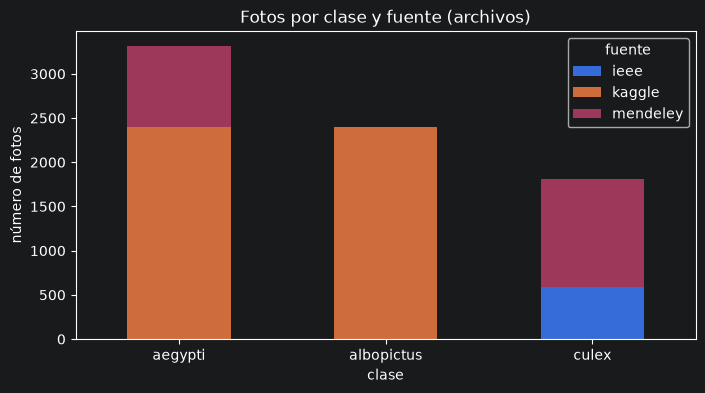

In [7]:
tabla = df.pivot_table(index='clase', columns='fuente', values='archivo', aggfunc='count', fill_value=0)
print(tabla)

tabla.plot(kind='bar', stacked=True, figsize=(8, 4), title='Fotos por clase y fuente (archivos)')
plt.ylabel('número de fotos')
plt.xticks(rotation=0)
plt.show()

## 3.3 Copias aumentadas vs fotos originales

In [8]:
# Cuantas copias hay por cada foto original en cada fuente #
copias = df.groupby(['fuente', 'clase', 'tipo']).size().unstack(fill_value=0)
copias['total'] = copias.sum(axis=1)
copias['copias_por_original'] = (copias['total'] / copias['original']).round(1)
copias

tipo                 copia  original  total  copias_por_original
fuente   clase                                                  
ieee     culex         220       374    594                  1.6
kaggle   aegypti      1800       603   2403                  4.0
         albopictus   1800       600   2400                  4.0
mendeley aegypti       900        15    915                 61.0
         culex        1200        20   1220                 61.0

fuente      ieee  kaggle  mendeley
clase                             
aegypti        0     603        15
albopictus     0     600         0
culex        374       0        20


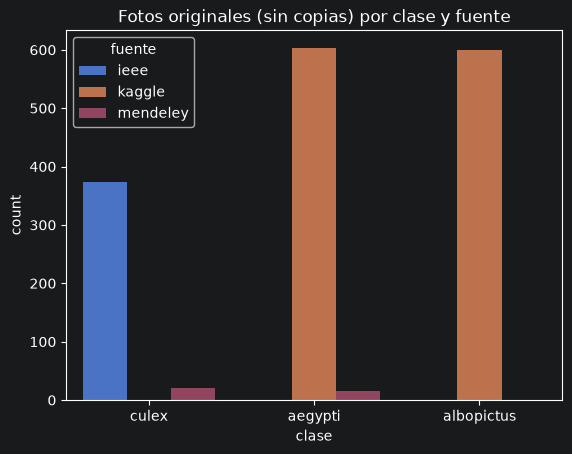

In [9]:
# Nos quedamos solo con las fotos originales: el aumento de datos se hace con capas dentro de la CNN (sección 4) #
originales = df[df['tipo'] == 'original']
print(originales.pivot_table(index='clase', columns='fuente', values='archivo', aggfunc='count', fill_value=0))

sns.countplot(data=originales, x='clase', hue='fuente')
plt.title('Fotos originales (sin copias) por clase y fuente')
plt.show()

## 3.4 Visualización de imágenes

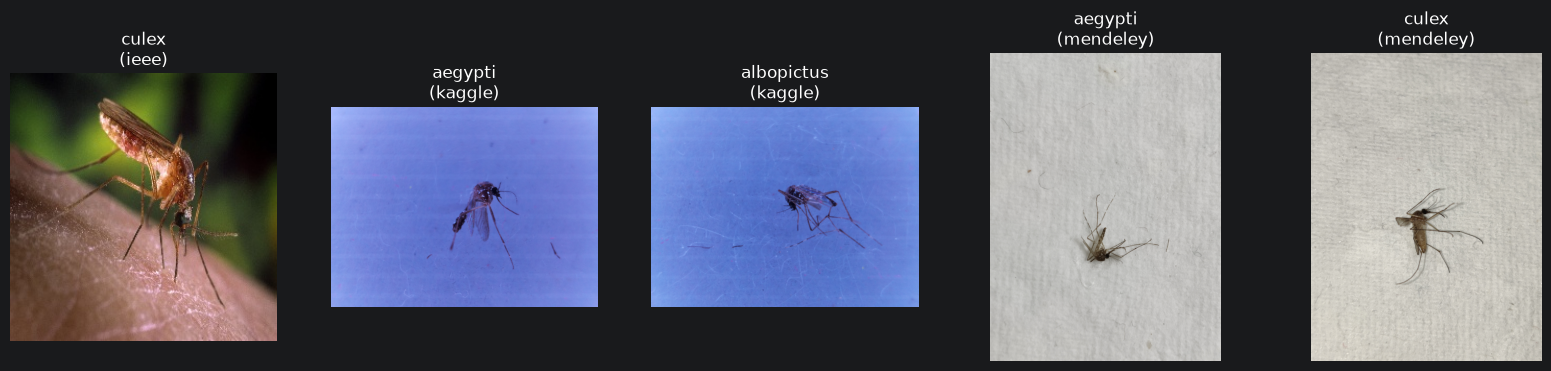

In [10]:
# Una foto de ejemplo de cada clase en cada fuente #
grupos = originales.groupby(['fuente', 'clase'])
fig, ejes = plt.subplots(1, len(grupos), figsize=(4 * len(grupos), 4))

for eje, ((fuente, clase), datos) in zip(ejes, grupos):
    eje.imshow(imread(datos['ruta'].iloc[0]))
    eje.set_title(f'{clase}\n({fuente})')
    eje.axis('off')
plt.show()

## 3.5 Calcular dimensiones promedio

In [11]:
# Tomamos hasta 40 fotos de cada fuente y clase, y medimos alto, ancho, canales de color y brillo #
muestra = originales.groupby(['fuente', 'clase']).sample(n=40, replace=True, random_state=101).drop_duplicates('ruta')

alto, ancho, canales, brillo = [], [], [], []
for ruta in muestra['ruta']:
    img = imread(ruta)
    alto.append(img.shape[0])
    ancho.append(img.shape[1])
    canales.append(img.shape[2] if img.ndim == 3 else 1)
    brillo.append(img[..., :3].mean() if img.ndim == 3 else img.mean())

muestra['alto'] = alto
muestra['ancho'] = ancho
muestra['canales'] = canales
muestra['brillo'] = brillo

print(muestra.groupby('fuente')[['alto', 'ancho']].mean().round(0))
print(muestra['canales'].value_counts())

            alto   ancho
fuente                  
ieee       256.0   256.0
kaggle    2464.0  3280.0
mendeley  3906.0  2930.0
canales
3    142
Name: count, dtype: int64


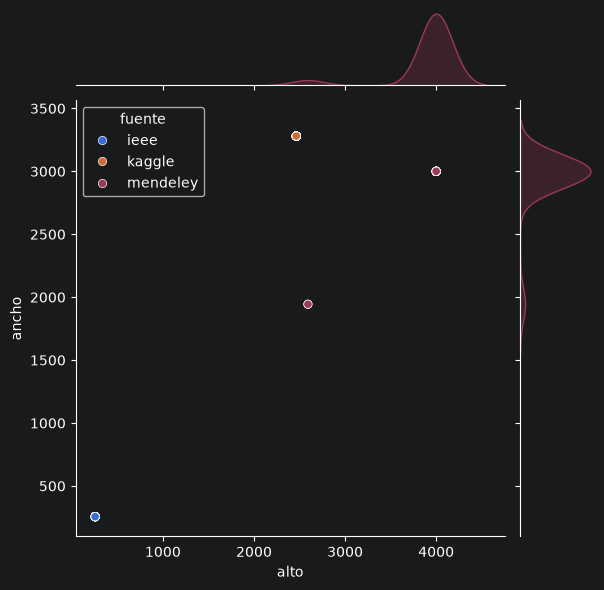

Alto promedio: 2193  Ancho promedio: 2418


In [12]:
sns.jointplot(data=muestra, x='alto', y='ancho', hue='fuente')
plt.show()

print('Alto promedio:', round(np.mean(muestra['alto'])), ' Ancho promedio:', round(np.mean(muestra['ancho'])))

In [13]:
# Las fotos tienen tamaños muy distintos entre fuentes; usaremos el tamaño que pide el enunciado #
image_shape = (128, 128, 3)

## 3.6 ¿El fondo delata la fuente? (brillo promedio)

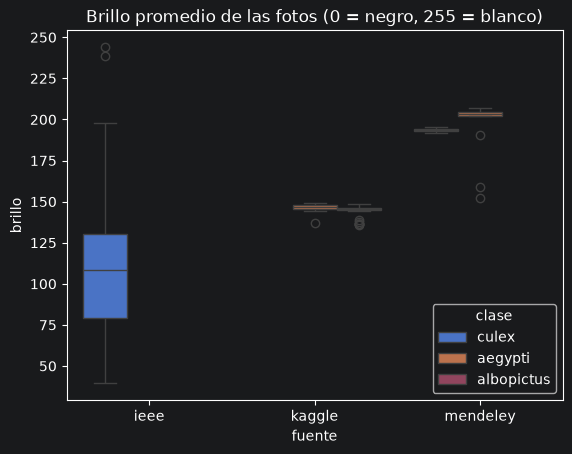

fuente    clase     
ieee      culex         110.0
kaggle    aegypti       146.0
          albopictus    144.0
mendeley  aegypti       196.0
          culex         194.0
Name: brillo, dtype: float64

In [14]:
sns.boxplot(data=muestra, x='fuente', y='brillo', hue='clase')
plt.title('Brillo promedio de las fotos (0 = negro, 255 = blanco)')
plt.show()

muestra.groupby(['fuente', 'clase'])['brillo'].mean().round(0)

## 3.7 Preparación de directorios train/test

In [15]:
# Solo originales. Kaggle: respetamos el split del autor. IEEE y Mendeley: 15 % al azar para test #
datos = df[df['tipo'] == 'original'].copy()

otras = datos['fuente'] != 'kaggle'
datos.loc[otras, 'split_autor'] = np.where(
    np.random.default_rng(101).random(otras.sum()) < 0.15, 'test', 'train')
datos = datos.rename(columns={'split_autor': 'split'})

datos.pivot_table(index=['split', 'fuente'], columns='clase', values='archivo', aggfunc='count', fill_value=0)

clase           aegypti  albopictus  culex
split fuente                              
test  ieee            0           0     60
      kaggle         90          90      0
      mendeley        5           0      3
train ieee            0           0    314
      kaggle        513         510      0
      mendeley       10           0     17

In [16]:
# Copiamos las fotos a la estructura que necesita flow_from_directory: dataset/train/<clase>/ y dataset/test/<clase>/ #
destino = '../data/raw/imagenes/dataset'

if os.path.exists(destino):
    shutil.rmtree(destino)          # Si ya existía, la borramos para empezar limpio #
for split in ['train', 'test']:
    for clase in ['aegypti', 'albopictus', 'culex']:
        os.makedirs(os.path.join(destino, split, clase))

for _, fila in datos.iterrows():
    carpeta_destino = os.path.join(destino, fila['split'], fila['clase'])
    shutil.copy(fila['ruta'], os.path.join(carpeta_destino, fila['fuente'] + '_' + fila['archivo']))

train_path = destino + '/train/'
test_path = destino + '/test/'
print(os.listdir(train_path), os.listdir(test_path))

['aegypti', 'albopictus', 'culex'] ['aegypti', 'albopictus', 'culex']


In [17]:
# ¿Cuántas imágenes tenemos en cada carpeta? #
for clase in os.listdir(train_path):
    print(clase, '- train:', len(os.listdir(train_path + clase)), ' test:', len(os.listdir(test_path + clase)))

aegypti - train: 523  test: 95
albopictus - train: 510  test: 90
culex - train: 331  test: 63


In [18]:
# Guardamos la lista de fotos usadas (fuente, clase, split) para el notebook de la CNN y el informe #
datos.drop(columns=['carpeta']).to_csv('../data/processed/inventario_imagenes.csv', index=False)

## 3.8 Conclusiones del EDA de imágenes

> **Nota:** las cifras de esta sección se corrigieron en 3.9 y 3.10.

- Se combinaron 3 fuentes (Kaggle, IEEE DataPort, Mendeley): 8,891 archivos. Se descartaron 810 fotos "Aedes" de IEEE (no indican especie) y 549 de Anopheles (no es una clase del proyecto).
- De los 7,532 archivos restantes, solo 1,612 son fotos originales: Kaggle trae cada foto rotada 4 veces e IEEE y Mendeley incluyen copias aumentadas (Mendeley, 61 copias por foto). Usamos solo las originales para que copias de una misma foto no queden repartidas entre train y test; el aumento de datos lo hará ImageDataGenerator.
- Split final: train 523 aegypti / 510 albopictus / 331 culex; test 95 / 90 / 63. En Kaggle se respetó el split del autor; en IEEE y Mendeley, 15 % al azar. Culex es la clase minoritaria → usar class weights.
- Riesgo de sesgo por fuente: aegypti y albopictus vienen casi todos de Kaggle (fondo azul, brillo ≈ 145) y el 95 % de culex viene de IEEE (fotos de campo, fondos variados). La CNN podría aprender el fondo en lugar del mosquito. Lo revisaremos en la matriz de confusión y lo discutiremos en el informe.
- Los tamaños varían mucho (256×256 en IEEE, ~2464×3280 en Kaggle, ~3906×2930 en Mendeley). Se redimensionará a 128×128 como sugiere el enunciado; en Kaggle el mosquito ocupa poca parte de la foto, lo que puede dificultar separar aegypti de albopictus.

## 3.9 Corrección: copias sin detectar y fotos del mismo espécimen

Al revisar `inventario_imagenes.csv` aparecieron dos problemas en el split de la sección 3.7:

- **IEEE:** `es_copia` solo detecta `_add`, pero también hay versiones `_blur`, `_flip`, `_rot1`, `_noise`, etc. Las 374 fotos "originales" de IEEE son en realidad 22 fotos con 17 versiones cada una, y sus versiones quedaron repartidas entre train y test.
- **Kaggle:** los archivos `albopictus10a`, `b`, `c` y `d` comparten número, así que parecen 4 fotos del mismo mosquito (falta confirmarlo mirando las fotos). En el split del autor, casi todas las de test tienen su número también en train.

Si la misma foto o el mismo mosquito está en train y test, el F1 sale inflado. Por eso volvemos a separar por **foto base**, de modo que todas las fotos de una base queden del mismo lado. Esta sección no necesita las imágenes para corregir la tabla; si están en la compu, también rehace las carpetas `train/` y `test/`.

Para correr esta sección basta con la celda de importaciones (sección 1); no hace falta repetir lo anterior.

In [19]:
# Cada archivo se identifica por su foto base: Culex10_blur -> Culex10, albopictus10a -> albopictus10 #
inventario = pd.read_csv('../data/processed/inventario_imagenes.csv')
inventario['ruta'] = inventario['ruta'].str.replace('\\', '/', regex=False)   # Rutas que sirven en cualquier compu #

nombres = inventario['archivo'].str.rsplit('.', n=1).str[0]
inventario['foto_base'] = nombres.str.extract(r'^([A-Za-z]+[0-9]+)', expand=False).fillna(nombres)   # Mendeley ya trae nombres únicos #

# Quitamos las versiones de IEEE (nombre distinto a su foto base) y los duplicados "- Copy" de Kaggle #
es_version = (inventario['fuente'] == 'ieee') & (nombres != inventario['foto_base'])
es_duplicado = nombres.str.contains(' - Copy', regex=False)
print('Versiones de IEEE quitadas:', es_version.sum(), ' Duplicados quitados:', es_duplicado.sum())

corregido = inventario[~(es_version | es_duplicado)].copy()
corregido.groupby(['clase', 'fuente']).agg(archivos=('archivo', 'count'), fotos_base=('foto_base', 'nunique'))

Versiones de IEEE quitadas: 352  Duplicados quitados: 3


archivos  fotos_base
clase      fuente                        
aegypti    kaggle         600         150
           mendeley        15          15
albopictus kaggle         600         151
culex      ieee            22          22
           mendeley        20          20

In [20]:
# 20 % de las fotos base de cada fuente y clase va a test; todas las fotos de una base quedan del mismo lado #
rng = np.random.default_rng(101)
corregido['split'] = 'train'
for _, grupo in corregido.groupby(['fuente', 'clase']):
    bases = np.sort(grupo['foto_base'].unique())
    bases_test = rng.choice(bases, size=round(0.2 * len(bases)), replace=False)
    corregido.loc[grupo.index[grupo['foto_base'].isin(bases_test)], 'split'] = 'test'

# Comprobación: ninguna foto base puede estar en train y en test a la vez #
fuga = set(corregido.loc[corregido['split'] == 'train', 'foto_base']) & set(corregido.loc[corregido['split'] == 'test', 'foto_base'])
print('Fotos base repetidas entre train y test:', len(fuga))

corregido.pivot_table(index=['split', 'fuente'], columns='clase', values='archivo', aggfunc='count', fill_value=0)

Fotos base repetidas entre train y test: 0


clase           aegypti  albopictus  culex
split fuente                              
test  ieee            0           0      4
      kaggle        120         120      0
      mendeley        3           0      4
train ieee            0           0     18
      kaggle        480         480      0
      mendeley       12           0     16

In [21]:
# Guardamos el inventario corregido y, si están las imágenes, rehacemos las carpetas para flow_from_directory #
corregido.to_csv('../data/processed/inventario_imagenes.csv', index=False)

mi_directorio = '../data/raw/imagenes/fuentes'
destino = '../data/raw/imagenes/dataset'
if os.path.exists(mi_directorio):
    if os.path.exists(destino):
        shutil.rmtree(destino)
    for split in ['train', 'test']:
        for clase in ['aegypti', 'albopictus', 'culex']:
            os.makedirs(os.path.join(destino, split, clase))
    for _, fila in corregido.iterrows():
        shutil.copy(fila['ruta'], os.path.join(destino, fila['split'], fila['clase'], fila['fuente'] + '_' + fila['archivo']))
    print('Carpetas rehechas en', destino)
else:
    print('No están las imágenes en esta compu: las carpetas se rehacen al correr esta celda donde sí estén.')

corregido.groupby(['split', 'clase']).size().unstack()

No están las imágenes en esta compu: las carpetas se rehacen al correr esta celda donde sí estén.


clase,aegypti,albopictus,culex
split,,,
test,123,120,8
train,492,480,34


## 3.10 Conclusiones corregidas (reemplazan las cifras de 3.8)

- Quedan **1,257 archivos y 358 fotos base**: 165 de aegypti, 151 de albopictus y solo **42 de culex** (22 de IEEE y 20 de Mendeley). Las 1,612 "originales" de 3.8 incluían 352 versiones de IEEE y 3 duplicados.
- Split final, sin fotos base repetidas: train 492 aegypti / 480 albopictus / 34 culex; test 123 / 120 / 8.
- Con solo 8 fotos de culex en test, un solo error mueve mucho el F1 de esa clase. Los class weights ayudan a entrenar, pero no reemplazan datos: conviene sumar Mosquito Alert antes de entrenar la CNN.
- Sigue el riesgo de sesgo por fuente: aegypti y albopictus vienen casi todas de Kaggle, y culex de IEEE y Mendeley. Mendeley es la única fuente con dos clases, así que sirve para revisar si la red mira el mosquito o el fondo.
- Falta confirmar, mirando las fotos, que las letras a, b, c y d de Kaggle son el mismo mosquito. Separar por número es seguro en cualquier caso.


# 4. Entrenamiento y evaluación de las CNN

El enunciado pide una **CNN propia desde cero (obligatoria)** y **MobileNetV2 con transfer learning** como comparación, y reportar el F1 macro de ambas (umbral ≥ 85 %).

Esta sección usa `inventario_imagenes.csv` (sección 3.9) y necesita las imágenes en `data/raw/imagenes/`. No están en el repositorio por su tamaño, y el `.gitignore` impide subirlas.

**Plan:**
1. Cargar el inventario y apartar validación por foto base, igual que el test.
2. Evaluar en validación los modelos que ya están guardados.
3. Entrenar la CNN propia mejorada (v2).
4. Elegir la CNN propia **solo con validación** y evaluar **una vez** en prueba.
5. Guardar los resultados calculados en `models/mosquitos_resultados.json`.

**No visto en clase:** `BatchNormalization`, `ReduceLROnPlateau`, capas de aumento de datos dentro del modelo (`RandomFlip`, `RandomRotation`, `RandomZoom`, `RandomContrast`), `GroupShuffleSplit` y `tf.data` para leer las fotos.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

sys.path.append('..')    # para importar las redes de src/train/cnn.py #
from src.train.cnn import crear_cnn, crear_cnn_v2, crear_mobilenet

CLASES = ['aegypti', 'albopictus', 'culex']
CARPETA_MODELOS = Path('../models')

# Interruptores: True = entrenar de nuevo; False = usar el modelo ya guardado #
ENTRENAR_CNN_V2 = True
ENTRENAR_MOBILENET = False    # MobileNetV2 ya cumple la meta; si se entrena, se guarda con otro nombre #

TAMANO_V2 = 192    # tamaño de las fotos para la CNN v2; si va muy lento, usar 160 #
EPOCAS = 80
BATCH_SIZE = 32
tf.keras.utils.set_random_seed(42)

## 4.1 Inventario, validación y pesos por clase

La validación se aparta **por foto base**: todas las versiones de una misma foto quedan del mismo lado. Es la misma separación que usaba `src/train/entrenar_mosquitos.py`.

In [2]:
inventario = pd.read_csv('../data/processed/inventario_imagenes.csv')
inventario['etiqueta'] = inventario['clase'].map({c: i for i, c in enumerate(CLASES)})

# Comprobar que todas las fotos están en su lugar #
faltantes = [r for r in inventario['ruta'] if not Path(r).is_file()]
print('Fotos en el inventario:', len(inventario), ' encontradas:', len(inventario) - len(faltantes))
if faltantes:
    raise FileNotFoundError(f'Faltan {len(faltantes)} fotos, por ejemplo {faltantes[0]}. '
                            'Copie las imágenes en data/raw/imagenes/ antes de correr esta sección.')

train_completo = inventario[inventario['split'] == 'train'].reset_index(drop=True)
test = inventario[inventario['split'] == 'test'].reset_index(drop=True)

# Validación: 15 % de las fotos base del entrenamiento #
grupos = (train_completo['fuente'].astype(str) + '_' + train_completo['clase'].astype(str)
          + '_' + train_completo['foto_base'].astype(str))
i_train, i_val = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
                      .split(train_completo, groups=grupos))
train = train_completo.iloc[i_train].reset_index(drop=True)
val = train_completo.iloc[i_val].reset_index(drop=True)

print(pd.DataFrame({'train': train['clase'].value_counts(),
                    'validación': val['clase'].value_counts(),
                    'prueba': test['clase'].value_counts()}))

# Pesos por clase: culex tiene muchas menos fotos #
pesos = compute_class_weight('balanced', classes=np.arange(3), y=train['etiqueta'])
pesos_clases = {i: float(p) for i, p in enumerate(pesos)}
print('Pesos por clase:', {CLASES[i]: round(p, 2) for i, p in pesos_clases.items()})

Fotos en el inventario: 1257  encontradas: 1257
            train  validación  prueba
clase                                
aegypti       414          78     123
albopictus    396          84     120
culex          32           2       8
Pesos por clase: {'aegypti': 0.68, 'albopictus': 0.71, 'culex': 8.77}


## 4.2 Leer las fotos y medir el F1

- La CNN propia recibe las fotos divididas entre 255 (valores de 0 a 1).
- MobileNetV2 recibe las fotos con su `preprocess_input` (valores de −1 a 1), igual que en la API.
- El tamaño de cada foto se toma del propio modelo, así cada red recibe lo que espera.

In [3]:
def leer_foto(ruta, tamano, mobilenet):
    foto = tf.io.decode_image(tf.io.read_file(ruta), channels=3, expand_animations=False)
    foto.set_shape([None, None, 3])
    foto = tf.image.resize(foto, (tamano, tamano))
    return preprocess_input(foto) if mobilenet else foto / 255.0


def crear_dataset(datos, tamano, mobilenet=False, mezclar=False):
    ds = tf.data.Dataset.from_tensor_slices((datos['ruta'].values, datos['etiqueta'].values.astype('int32')))
    if mezclar:
        ds = ds.shuffle(len(datos), seed=42)
    ds = ds.map(lambda r, e: (leer_foto(r, tamano, mobilenet), e), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


def evaluar(modelo, datos, mobilenet=False):
    # Devuelve las predicciones y el F1 macro (promedio simple del F1 de las 3 especies) #
    tamano = modelo.input_shape[1]
    pred = np.argmax(modelo.predict(crear_dataset(datos, tamano, mobilenet), verbose=0), axis=1)
    return pred, f1_score(datos['etiqueta'], pred, average='macro', labels=[0, 1, 2], zero_division=0)


def graficar_historia(historia, titulo):
    fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
    for eje, (clave, nombre) in zip(ejes, [('loss', 'Error'), ('accuracy', 'Aciertos')]):
        eje.plot(historia.history[clave], label='entrenamiento')
        eje.plot(historia.history['val_' + clave], label='validación')
        eje.set_title(f'{titulo}: {nombre}')
        eje.set_xlabel('época')
        eje.legend()
    plt.show()

## 4.3 Modelos ya guardados, evaluados en validación

Hay dos CNN propias guardadas: `cnn_mosquitos.keras` (la sugerida, sin aumento de datos) y `cnn_mosquitos_mejorada.keras` (la sugerida con aumento de datos). Antes no se sabía cuál dio el 53.97 %; aquí se miden las dos con los mismos datos.

In [4]:
guardados = {
    'CNN propia sugerida': ('cnn_mosquitos.keras', False),
    'CNN propia sugerida + aumento': ('cnn_mosquitos_mejorada.keras', False),
    'MobileNetV2': ('mobilenet_mosquitos.keras', True),
}

resultados_val = {}
for nombre, (archivo, mobilenet) in guardados.items():
    if (CARPETA_MODELOS / archivo).exists():
        modelo = tf.keras.models.load_model(CARPETA_MODELOS / archivo, compile=False)
        _, f1 = evaluar(modelo, val, mobilenet)
        resultados_val[nombre] = {'archivo': archivo, 'mobilenet': mobilenet, 'f1_val': f1}
        print(f'{nombre} ({archivo}): F1 macro en validación = {f1:.3f}')

CNN propia sugerida (cnn_mosquitos.keras): F1 macro en validación = 0.445
CNN propia sugerida + aumento (cnn_mosquitos_mejorada.keras): F1 macro en validación = 0.452
MobileNetV2 (mobilenet_mosquitos.keras): F1 macro en validación = 0.865


## 4.4 Entrenar la CNN propia mejorada (v2)

Sigue siendo **desde cero**: no usa pesos preentrenados. Cambios frente a la sugerida (ver `crear_cnn_v2` en `src/train/cnn.py`):
- Fotos de 192 × 192 en vez de 128 × 128, para ver detalles como las escamas blancas del tórax, que distinguen a aegypti de albopictus.
- Dos capas Conv2D por bloque, un cuarto bloque de 256 filtros y BatchNormalization.
- Más aumento de datos: giros en las dos direcciones, rotación, zoom y contraste.
- EarlyStopping con más paciencia y ReduceLROnPlateau, que baja la tasa de aprendizaje cuando la validación deja de mejorar.

Se guarda como `cnn_mosquitos_v2.keras`, sin reemplazar los modelos anteriores.

Epoch 1/80
27/27 - 112s - 4s/step - accuracy: 0.5665 - loss: 0.6594 - val_accuracy: 0.0000e+00 - val_loss: 1.9033 - learning_rate: 0.0010
Epoch 2/80
27/27 - 112s - 4s/step - accuracy: 0.6425 - loss: 0.5282 - val_accuracy: 0.5244 - val_loss: 0.7762 - learning_rate: 0.0010
Epoch 3/80
27/27 - 100s - 4s/step - accuracy: 0.7233 - loss: 0.4970 - val_accuracy: 0.5122 - val_loss: 1.0655 - learning_rate: 0.0010
Epoch 4/80
27/27 - 96s - 4s/step - accuracy: 0.7470 - loss: 0.4153 - val_accuracy: 0.5122 - val_loss: 4.1765 - learning_rate: 0.0010
Epoch 5/80
27/27 - 87s - 3s/step - accuracy: 0.8266 - loss: 0.3396 - val_accuracy: 0.5244 - val_loss: 4.2365 - learning_rate: 0.0010
Epoch 6/80
27/27 - 87s - 3s/step - accuracy: 0.8765 - loss: 0.2447 - val_accuracy: 0.5244 - val_loss: 1.0497 - learning_rate: 0.0010
Epoch 7/80
27/27 - 95s - 4s/step - accuracy: 0.8800 - loss: 0.2760 - val_accuracy: 0.4756 - val_loss: 2.7376 - learning_rate: 5.0000e-04
Epoch 8/80
27/27 - 83s - 3s/step - accuracy: 0.9169 - loss

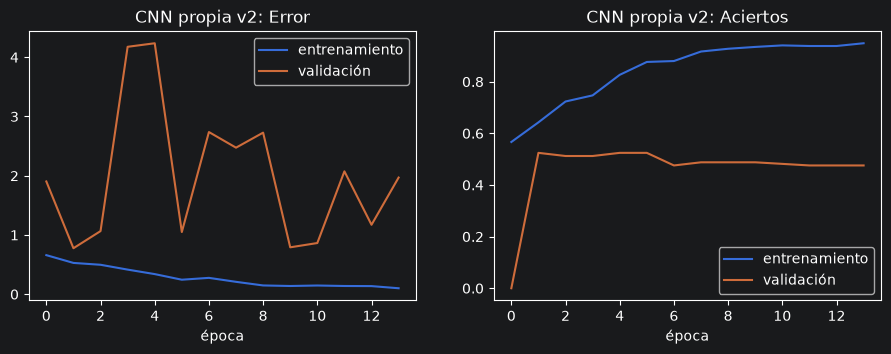

CNN propia v2: F1 macro en validación = 0.244


In [5]:
archivo_v2 = 'cnn_mosquitos_v2.keras'

if ENTRENAR_CNN_V2:
    modelo_v2 = crear_cnn_v2(tamano=TAMANO_V2)
    historia_v2 = modelo_v2.fit(
        crear_dataset(train, TAMANO_V2, mezclar=True),
        validation_data=crear_dataset(val, TAMANO_V2),
        epochs=EPOCAS,
        class_weight=pesos_clases,
        shuffle=False,    # el dataset ya viene mezclado #
        callbacks=[EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True),
                   ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4),
                   ModelCheckpoint(str(CARPETA_MODELOS / archivo_v2), monitor='val_loss', save_best_only=True)],
        verbose=2)
    print('Épocas entrenadas:', len(historia_v2.history['loss']))
    graficar_historia(historia_v2, 'CNN propia v2')

if (CARPETA_MODELOS / archivo_v2).exists():
    modelo_v2 = tf.keras.models.load_model(CARPETA_MODELOS / archivo_v2, compile=False)
    _, f1 = evaluar(modelo_v2, val)
    resultados_val['CNN propia v2'] = {'archivo': archivo_v2, 'mobilenet': False, 'f1_val': f1}
    print(f'CNN propia v2: F1 macro en validación = {f1:.3f}')

## 4.5 (Opcional) Volver a entrenar MobileNetV2

Normalmente no hace falta: el modelo guardado ya cumple la meta y es el que usa la API. Si se activa `ENTRENAR_MOBILENET`, el nuevo modelo se guarda como `mobilenet_mosquitos_nueva.keras`, para no cambiar el de la API.

In [6]:
if ENTRENAR_MOBILENET:
    modelo_mb = crear_mobilenet()
    historia_mb = modelo_mb.fit(
        crear_dataset(train, 128, mobilenet=True, mezclar=True),
        validation_data=crear_dataset(val, 128, mobilenet=True),
        epochs=30,
        class_weight=pesos_clases,
        shuffle=False,    # el dataset ya viene mezclado #
        callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                   ModelCheckpoint(str(CARPETA_MODELOS / 'mobilenet_mosquitos_nueva.keras'),
                                   monitor='val_loss', save_best_only=True)],
        verbose=2)
    graficar_historia(historia_mb, 'MobileNetV2')
    _, f1 = evaluar(modelo_mb, val, mobilenet=True)
    print(f'MobileNetV2 nueva: F1 macro en validación = {f1:.3f}')
else:
    print('Se usa la MobileNetV2 guardada (mobilenet_mosquitos.keras).')

Se usa la MobileNetV2 guardada (mobilenet_mosquitos.keras).


## 4.6 Elegir la CNN propia con validación

Se elige la CNN propia con **mayor F1 macro en validación**. La prueba no se usa para elegir: si se usara, el resultado final estaría inflado.

In [7]:
tabla_val = (pd.DataFrame([{'modelo': n, 'archivo': v['archivo'], 'F1 macro validación': round(v['f1_val'], 3)}
                           for n, v in resultados_val.items()])
             .sort_values('F1 macro validación', ascending=False))
print(tabla_val.to_string(index=False))

propias = {n: v for n, v in resultados_val.items() if not v['mobilenet']}
elegida = max(propias, key=lambda n: propias[n]['f1_val'])
print('\nCNN propia elegida con validación:', elegida, f"({propias[elegida]['archivo']})")

                       modelo                      archivo  F1 macro validación
                  MobileNetV2    mobilenet_mosquitos.keras                0.865
CNN propia sugerida + aumento cnn_mosquitos_mejorada.keras                0.452
          CNN propia sugerida          cnn_mosquitos.keras                0.445
                CNN propia v2       cnn_mosquitos_v2.keras                0.244

CNN propia elegida con validación: CNN propia sugerida + aumento (cnn_mosquitos_mejorada.keras)


## 4.7 Evaluación final en prueba (una sola vez)

Se evalúan la CNN propia elegida y MobileNetV2 con las 251 fotos de prueba. La matriz de confusión muestra con qué especie se confunde cada una: las filas son lo correcto y las columnas lo que respondió la red.

===== CNN propia sugerida + aumento (cnn_mosquitos_mejorada.keras): F1 macro en prueba = 0.5029  (50.29%)
              precision    recall  f1-score   support

     aegypti       0.00      0.00      0.00       123
  albopictus       0.50      1.00      0.67       120
       culex       0.73      1.00      0.84         8

    accuracy                           0.51       251
   macro avg       0.41      0.67      0.50       251
weighted avg       0.26      0.51      0.35       251

===== MobileNetV2 (mobilenet_mosquitos.keras): F1 macro en prueba = 0.8830  (88.30%)
              precision    recall  f1-score   support

     aegypti       0.91      0.84      0.87       123
  albopictus       0.86      0.92      0.89       120
       culex       0.80      1.00      0.89         8

    accuracy                           0.88       251
   macro avg       0.86      0.92      0.88       251
weighted avg       0.88      0.88      0.88       251



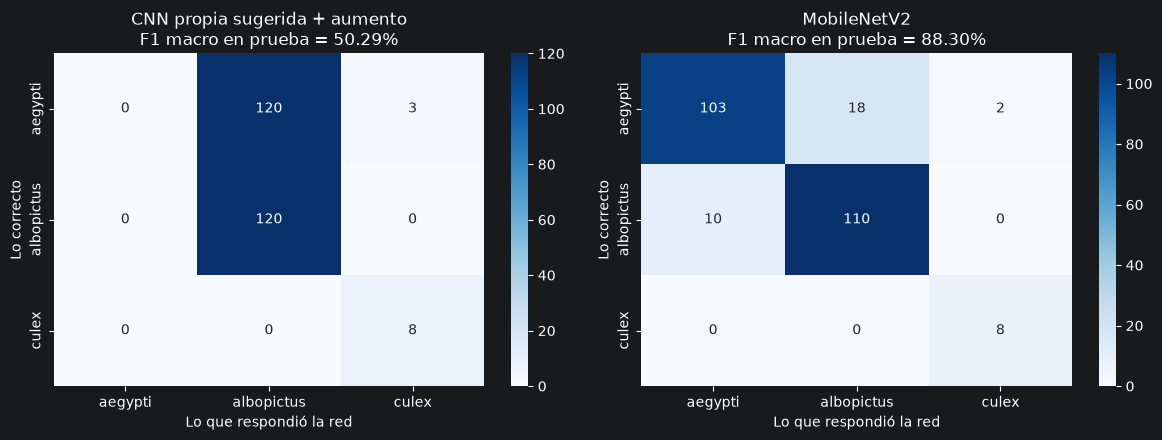

CNN propia sugerida + aumento: 50.29% -> no cumple la meta de 85 %
MobileNetV2: 88.30% -> cumple la meta de 85 %


In [8]:
finales = {elegida: propias[elegida], 'MobileNetV2': resultados_val['MobileNetV2']}
resumen = {}

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
for eje, (nombre, info) in zip(ejes, finales.items()):
    modelo = tf.keras.models.load_model(CARPETA_MODELOS / info['archivo'], compile=False)
    pred, f1 = evaluar(modelo, test, info['mobilenet'])
    f1_clase = f1_score(test['etiqueta'], pred, average=None, labels=[0, 1, 2], zero_division=0)
    matriz = confusion_matrix(test['etiqueta'], pred, labels=[0, 1, 2])

    print(f'===== {nombre} ({info["archivo"]}): F1 macro en prueba = {f1:.4f}  ({f1:.2%})')
    print(classification_report(test['etiqueta'], pred, labels=[0, 1, 2], target_names=CLASES, zero_division=0))

    sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', xticklabels=CLASES, yticklabels=CLASES, ax=eje)
    eje.set_title(f'{nombre}\nF1 macro en prueba = {f1:.2%}')
    eje.set_xlabel('Lo que respondió la red')
    eje.set_ylabel('Lo correcto')

    resumen[info['archivo']] = {'f1_macro': round(float(f1), 4),
                                'f1_por_clase': {c: round(float(v), 2) for c, v in zip(CLASES, f1_clase)},
                                'matriz_confusion': matriz.tolist()}
plt.tight_layout()
plt.show()

for nombre, info in finales.items():
    f1 = resumen[info['archivo']]['f1_macro']
    print(f"{nombre}: {f1:.2%} -> {'cumple' if f1 >= 0.85 else 'no cumple'} la meta de 85 %")

## 4.8 Guardar los resultados calculados

`models/mosquitos_resultados.json` ahora guarda los valores **calculados** aquí, no escritos a mano. La app y el informe toman las cifras de este archivo.

In [9]:
archivo_propia = propias[elegida]['archivo']
resultados = {
    'cnn_propia': {'modelo': archivo_propia, 'version': elegida, **resumen[archivo_propia]},
    'mobilenetv2': {'modelo': 'mobilenet_mosquitos.keras', **resumen['mobilenet_mosquitos.keras']},
    'evaluacion': {'conjunto': 'test', 'total_imagenes': int(len(test)), 'clases': CLASES,
                   'meta_f1_macro': 0.85, 'calculado_en': 'notebooks/02_CNN_Mosquitos.ipynb, sección 4'},
}
with open(CARPETA_MODELOS / 'mosquitos_resultados.json', 'w', encoding='utf-8') as archivo:
    json.dump(resultados, archivo, indent=4, ensure_ascii=False)
print(json.dumps(resultados, indent=2, ensure_ascii=False))

{
  "cnn_propia": {
    "modelo": "cnn_mosquitos_mejorada.keras",
    "version": "CNN propia sugerida + aumento",
    "f1_macro": 0.5029,
    "f1_por_clase": {
      "aegypti": 0.0,
      "albopictus": 0.67,
      "culex": 0.84
    },
    "matriz_confusion": [
      [
        0,
        120,
        3
      ],
      [
        0,
        120,
        0
      ],
      [
        0,
        0,
        8
      ]
    ]
  },
  "mobilenetv2": {
    "modelo": "mobilenet_mosquitos.keras",
    "f1_macro": 0.883,
    "f1_por_clase": {
      "aegypti": 0.87,
      "albopictus": 0.89,
      "culex": 0.89
    },
    "matriz_confusion": [
      [
        103,
        18,
        2
      ],
      [
        10,
        110,
        0
      ],
      [
        0,
        0,
        8
      ]
    ]
  },
  "evaluacion": {
    "conjunto": "test",
    "total_imagenes": 251,
    "clases": [
      "aegypti",
      "albopictus",
      "culex"
    ],
    "meta_f1_macro": 0.85,
    "calculado_en": "notebooks/02_CN

## 4.9 Conclusiones del entrenamiento

Se entrenaron y evaluaron diferentes arquitecturas de redes neuronales convolucionales para clasificar imágenes de mosquitos de las especies *Aedes aegypti*, *Aedes albopictus* y *Culex*.

La CNN propia original obtuvo un F1 macro de 44.5 % en validación, mientras que la versión con aumento de datos alcanzó un 45.2 %. Por su parte, la nueva CNN v2 obtuvo un F1 macro de 24.4 % en validación, evidenciando dificultades para generalizar a imágenes no utilizadas durante el entrenamiento.

La CNN propia con aumento de datos fue seleccionada como la mejor arquitectura propia y alcanzó un F1 macro de 50.29 % en el conjunto de prueba, por debajo de la meta establecida del 85 %.

En contraste, MobileNetV2, utilizando aprendizaje por transferencia, obtuvo un F1 macro de 86.5 % en validación y **88.30 % en prueba**, superando la meta del proyecto. Este resultado demuestra que el aprovechamiento de características previamente aprendidas mediante transferencia de aprendizaje fue más efectivo que el entrenamiento de las CNN propias con los datos disponibles.

El análisis de las matrices de confusión mostró que la CNN propia presentó dificultades importantes para diferenciar *Aedes aegypti* de *Aedes albopictus*. Aunque MobileNetV2 consiguió resultados considerablemente mejores, el número reducido de imágenes de *Culex* en el conjunto de prueba constituye una limitación para evaluar su capacidad de generalización en esta especie.

Se concluye que **MobileNetV2 es el modelo más adecuado para integrar al sistema VectorIA**, mientras que las CNN propias permiten documentar las dificultades de entrenar modelos desde cero con conjuntos de datos limitados y desbalanceados.

# 5. Experimento: CNN propia con las fotos recortadas alrededor del mosquito

La matriz de confusión de la sección 4.7 mostró el problema de la CNN propia: respondió *albopictus* en 120 de las 123 fotos de *aegypti*. Estas dos especies se distinguen por el dibujo de escamas blancas del tórax (*aegypti* tiene una figura de lira y *albopictus* una sola línea en el centro). En las fotos de Kaggle el mosquito ocupa una parte pequeña de una foto de unos 2464 × 3280 píxeles, así que al reducirla a 128 o 192 píxeles ese dibujo casi desaparece. MobileNetV2 lo compensa con lo que aprendió de millones de imágenes; una red desde cero no.

**Idea:** antes de reducir cada foto, recortarla alrededor del mosquito, para que la red vea el tórax con más detalle. La red es la misma v2 (`crear_cnn_v2`, desde cero), y la mejor época se elige con el F1 macro en validación, no con la pérdida (en la sección 4.4 la pérdida saltaba mucho y la v2 se quedó con un modelo malo).

**Fotos usadas:** las 22 fotos de *Culex* de IEEE DataPort no se pudieron volver a descargar (la página pide una suscripción de pago), así que este experimento usa las otras 1,235 fotos con **la misma separación** de la sección 4.1. Para comparar de forma justa, todos los modelos se evalúan con **las mismas fotos**. Como la validación se queda sin *Culex* (sus 2 fotos eran de IEEE), el F1 de validación se calcula con *aegypti* y *albopictus*, que es justo donde está el problema.

Los resultados oficiales de la sección 4 no se cambian.

**No visto en clase:** buscar el mosquito por su distancia al color del fondo, `scipy.ndimage` (manchas conectadas) y un *callback* propio que calcula el F1 al final de cada época.

## 5.1 Las mismas fotos de la sección 4.1, sin las que faltan

In [22]:
from PIL import Image
from scipy import ndimage

inventario_x = pd.read_csv('../data/processed/inventario_imagenes.csv')
inventario_x['etiqueta'] = inventario_x['clase'].map({c: i for i, c in enumerate(CLASES)})

# Misma separación que en 4.1 (mismas fotos base y misma semilla) #
train_completo_x = inventario_x[inventario_x['split'] == 'train'].reset_index(drop=True)
grupos_x = (train_completo_x['fuente'].astype(str) + '_' + train_completo_x['clase'].astype(str)
            + '_' + train_completo_x['foto_base'].astype(str))
i_train, i_val = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
                      .split(train_completo_x, groups=grupos_x))
partes_x = {'train': train_completo_x.iloc[i_train],
            'validación': train_completo_x.iloc[i_val],
            'prueba': inventario_x[inventario_x['split'] == 'test']}

# Se dejan fuera las fotos que no están en la computadora (las de IEEE) #
def solo_existentes(datos):
    return datos[[Path(r).is_file() for r in datos['ruta']]].reset_index(drop=True)

train_x, val_x, test_x = (solo_existentes(d) for d in partes_x.values())
for (nombre, d), d_x in zip(partes_x.items(), (train_x, val_x, test_x)):
    faltan = d[~d['ruta'].isin(d_x['ruta'])]
    print(f'{nombre}: {len(d_x)} fotos (faltan {len(faltan)}: {faltan.groupby(["fuente", "clase"]).size().to_dict()})')

print(pd.DataFrame({'train': train_x['clase'].value_counts(),
                    'validación': val_x['clase'].value_counts(),
                    'prueba': test_x['clase'].value_counts()}).fillna(0).astype(int))

pesos_x = compute_class_weight('balanced', classes=np.arange(3), y=train_x['etiqueta'])
pesos_clases_x = {i: float(p) for i, p in enumerate(pesos_x)}
CLASES_VAL = sorted(val_x['etiqueta'].unique())    # especies que hay en validación #
print('Pesos por clase:', {CLASES[i]: round(p, 2) for i, p in pesos_clases_x.items()})
print('Especies en validación:', [CLASES[i] for i in CLASES_VAL])

train: 826 fotos (faltan 16: {('ieee', 'culex'): 16})
validación: 162 fotos (faltan 2: {('ieee', 'culex'): 2})
prueba: 247 fotos (faltan 4: {('ieee', 'culex'): 4})
            train  validación  prueba
clase                                
aegypti       414          78     123
albopictus    396          84     120
culex          16           0       4
Pesos por clase: {'aegypti': 0.67, 'albopictus': 0.7, 'culex': 17.21}
Especies en validación: ['aegypti', 'albopictus']


## 5.2 Recortar cada foto alrededor del mosquito

1. Se reduce una copia de la foto y se toma como **color del fondo** la mediana de sus píxeles (el fondo ocupa casi toda la foto).
2. Los píxeles que se alejan mucho de ese color son el mosquito; se queda la **mancha más grande** que no toca el borde (en las esquinas la luz cambia y forma manchas falsas).
3. Se recorta un cuadrado alrededor de esa mancha, con margen, desde la foto original (con toda su resolución), y se guarda a 256 × 256 en `data/raw/imagenes/recortes/` (no se sube al repositorio).

Si no se encuentra una mancha clara, se usa la foto completa. El recorte no usa la especie y es igual para entrenamiento, validación y prueba: es solo preprocesamiento.

In [23]:
CARPETA_RECORTES = Path('../data/raw/imagenes/recortes')
LADO_RECORTE = 256
UMBRAL_COLOR = 60    # distancia al color del fondo (de 0 a 441) para considerar que un píxel es del mosquito #
MARGEN = 0.35        # margen alrededor del mosquito #


def caja_mosquito(foto):
    # Devuelve (izquierda, arriba, lado) del cuadrado con el mosquito, en la foto original, o None si no lo encuentra #
    ancho, alto = foto.size
    chica = foto.copy()
    chica.thumbnail((400, 400))
    escala = ancho / chica.size[0]
    pixeles = np.asarray(chica, dtype=float)
    fondo = np.median(pixeles.reshape(-1, 3), axis=0)
    distancia = np.sqrt(((pixeles - fondo) ** 2).sum(axis=2))
    mascara = ndimage.binary_opening(distancia > UMBRAL_COLOR, iterations=2)
    manchas, cantidad = ndimage.label(mascara)
    if cantidad == 0:
        return None
    tamanos = ndimage.sum(mascara, manchas, range(1, cantidad + 1))
    borde = np.unique(np.concatenate([manchas[0], manchas[-1], manchas[:, 0], manchas[:, -1]]))
    tamanos[borde[borde > 0] - 1] = 0    # se descartan las manchas que tocan el borde (luz desigual en las esquinas) #
    mayor = int(np.argmax(tamanos)) + 1
    if tamanos[mayor - 1] < 0.002 * mascara.size:    # mancha demasiado chica #
        return None
    filas, columnas = np.where(manchas == mayor)
    y0, y1, x0, x1 = filas.min(), filas.max(), columnas.min(), columnas.max()
    lado = max(y1 - y0, x1 - x0) * (1 + MARGEN) * escala
    lado = max(lado, 0.3 * min(ancho, alto))    # tamaño mínimo, para que todos los recortes tengan una escala parecida #
    if lado > 0.9 * min(ancho, alto):    # la mancha ocupa casi toda la foto #
        return None
    centro_x, centro_y = (x0 + x1) / 2 * escala, (y0 + y1) / 2 * escala
    izquierda = int(np.clip(centro_x - lado / 2, 0, ancho - lado))
    arriba = int(np.clip(centro_y - lado / 2, 0, alto - lado))
    return izquierda, arriba, int(lado)


def recortar(ruta_origen, ruta_destino):
    foto = Image.open(ruta_origen)
    foto.draft('RGB', (foto.size[0] // 2, foto.size[1] // 2))    # leer el JPG a la mitad de tamaño: más rápido y sobra resolución #
    foto = foto.convert('RGB')
    caja = caja_mosquito(foto)
    encontrado = caja is not None
    if not encontrado:    # la foto completa, centrada en un cuadrado #
        lado = min(foto.size)
        caja = ((foto.size[0] - lado) // 2, (foto.size[1] - lado) // 2, lado)
    izquierda, arriba, lado = caja
    recorte = foto.crop((izquierda, arriba, izquierda + lado, arriba + lado))
    recorte = recorte.resize((LADO_RECORTE, LADO_RECORTE), Image.LANCZOS)
    ruta_destino.parent.mkdir(parents=True, exist_ok=True)
    recorte.save(ruta_destino, quality=95)
    return encontrado


# Copias de las tablas con la ruta del recorte en la columna 'ruta' (así sirven crear_dataset y evaluar de 4.2) #
def con_recorte(datos):
    copia = datos.copy()
    copia['ruta'] = [str(CARPETA_RECORTES / Path(r).relative_to('../data/raw/imagenes/fuentes')) for r in datos['ruta']]
    return copia

train_r, val_r, test_r = con_recorte(train_x), con_recorte(val_x), con_recorte(test_x)

todas_x = pd.concat([train_x, val_x, test_x], ignore_index=True)
todas_r = pd.concat([train_r, val_r, test_r], ignore_index=True)
encontrados = [recortar(Path(o), Path(d)) for o, d in zip(todas_x['ruta'], todas_r['ruta'])]
todas_x['mosquito_encontrado'] = encontrados
print(f'Se encontró el mosquito en {sum(encontrados)} de {len(encontrados)} fotos; en el resto se usa la foto completa.')
print(todas_x.groupby('fuente')['mosquito_encontrado'].mean().round(3))

Se encontró el mosquito en 1235 de 1235 fotos; en el resto se usa la foto completa.
fuente
kaggle      1.0
mendeley    1.0
Name: mosquito_encontrado, dtype: float64


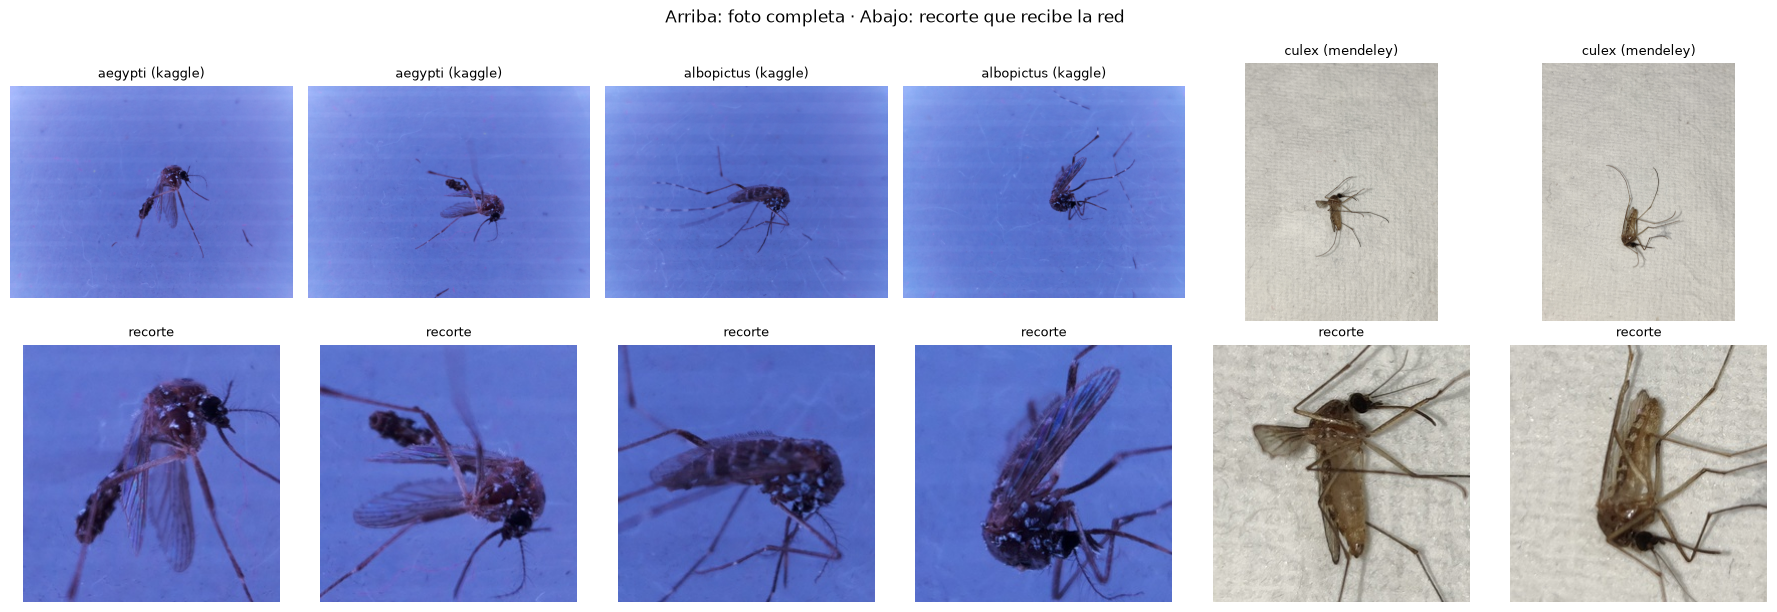

In [24]:
# Antes y después: dos fotos de cada especie #
ejemplos = list(todas_x.groupby('clase').head(2).index)[:6]
fig, ejes = plt.subplots(2, len(ejemplos), figsize=(3 * len(ejemplos), 6.2))
for columna, k in enumerate(ejemplos):
    original, recorte = todas_x.iloc[k], todas_r.iloc[k]
    ejes[0, columna].imshow(Image.open(original['ruta']))
    ejes[0, columna].set_title(f"{original['clase']} ({original['fuente']})", fontsize=9)
    ejes[1, columna].imshow(Image.open(recorte['ruta']))
    ejes[1, columna].set_title('recorte', fontsize=9)
for eje in ejes.ravel():
    eje.axis('off')
plt.suptitle('Arriba: foto completa · Abajo: recorte que recibe la red')
plt.tight_layout()
plt.show()

## 5.3 Entrenar la CNN propia con recorte

La misma `crear_cnn_v2` de la sección 4.4 (desde cero), con recortes de 128 × 128, el tamaño que sugiere el enunciado: como el recorte ya agranda al mosquito, el tórax se sigue viendo. Dos cambios más en el entrenamiento:

- La mejor época se elige con el **F1 macro en validación** (con *aegypti* y *albopictus*), no con la pérdida.
- La parada anticipada no actúa antes de la época 8, para que la red tenga tiempo de empezar a aprender, y el entrenamiento llega como máximo a 40 épocas.

Se guarda como `cnn_mosquitos_recorte.keras`, sin reemplazar los modelos anteriores.

Epoch 1/40


26/26 - 36s - 1s/step - accuracy: 0.6695 - loss: 0.8194 - val_accuracy: 0.4691 - val_loss: 0.9217 - val_f1: 0.3193 - learning_rate: 0.0010


Epoch 2/40


26/26 - 25s - 977ms/step - accuracy: 0.7603 - loss: 0.5140 - val_accuracy: 0.4815 - val_loss: 1.4570 - val_f1: 0.3250 - learning_rate: 0.0010


Epoch 3/40


26/26 - 25s - 977ms/step - accuracy: 0.8172 - loss: 0.3981 - val_accuracy: 0.4815 - val_loss: 1.5607 - val_f1: 0.3250 - learning_rate: 0.0010


... (71 outputs left out)

26/26 - 25s - 951ms/step - accuracy: 0.9492 - loss: 0.1142 - val_accuracy: 0.8889 - val_loss: 0.3015 - val_f1: 0.8944 - learning_rate: 6.2500e-05


Epoch 40/40


26/26 - 25s - 958ms/step - accuracy: 0.9564 - loss: 0.0996 - val_accuracy: 0.9506 - val_loss: 0.1540 - val_f1: 0.9560 - learning_rate: 6.2500e-05


Épocas entrenadas: 40 | mejor época: 38 | mejor F1 en validación: 0.956


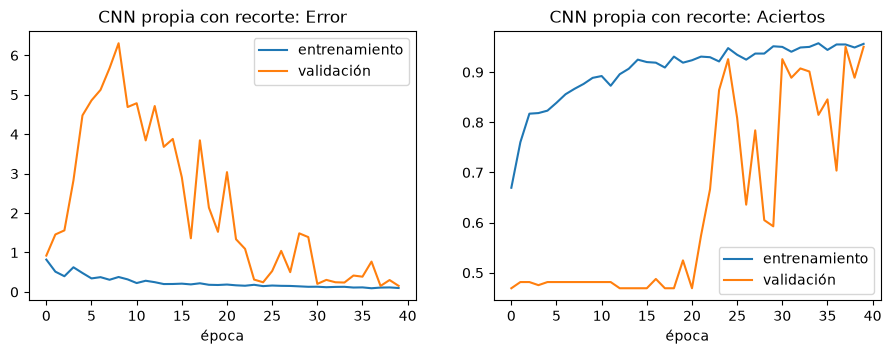

In [25]:
archivo_recorte = 'cnn_mosquitos_recorte.keras'
TAMANO_RECORTE = 128
EPOCAS_RECORTE = 40
ENTRENAR_CNN_RECORTE = True


# F1 macro en validación al final de cada época, para elegir la mejor época con la métrica del enunciado #
class F1Validacion(tf.keras.callbacks.Callback):
    def __init__(self, datos, tamano):
        super().__init__()
        self.datos = crear_dataset(datos, tamano)
        self.reales = datos['etiqueta'].values

    def on_epoch_end(self, epoch, logs=None):
        pred = np.argmax(self.model.predict(self.datos, verbose=0), axis=1)
        logs['val_f1'] = f1_score(self.reales, pred, average='macro', labels=CLASES_VAL, zero_division=0)


if ENTRENAR_CNN_RECORTE:
    tf.keras.utils.set_random_seed(42)
    modelo_recorte = crear_cnn_v2(tamano=TAMANO_RECORTE)
    historia_recorte = modelo_recorte.fit(
        crear_dataset(train_r, TAMANO_RECORTE, mezclar=True),
        validation_data=crear_dataset(val_r, TAMANO_RECORTE),
        epochs=EPOCAS_RECORTE,
        class_weight=pesos_clases_x,
        shuffle=False,    # el dataset ya viene mezclado #
        callbacks=[F1Validacion(val_r, TAMANO_RECORTE),    # va primero, para que los demás vean val_f1 #
                   EarlyStopping(monitor='val_f1', mode='max', patience=10, start_from_epoch=8,
                                 restore_best_weights=True),
                   ReduceLROnPlateau(monitor='val_f1', mode='max', factor=0.5, patience=5, min_lr=1e-5),
                   ModelCheckpoint(str(CARPETA_MODELOS / archivo_recorte), monitor='val_f1', mode='max',
                                   save_best_only=True)],
        verbose=2)
    f1_epocas = historia_recorte.history['val_f1']
    print('Épocas entrenadas:', len(f1_epocas), '| mejor época:', int(np.argmax(f1_epocas)) + 1,
          '| mejor F1 en validación:', round(max(f1_epocas), 3))
    graficar_historia(historia_recorte, 'CNN propia con recorte')

## 5.4 Comparación en validación

Todos los modelos con las mismas fotos de validación: la CNN con recorte recibe los recortes, y los demás la foto completa, como se entrenaron. Se elige la CNN propia con mayor F1 en validación.

In [26]:
modelos_x = {
    'CNN propia sugerida': ('cnn_mosquitos.keras', False, False),
    'CNN propia sugerida + aumento': ('cnn_mosquitos_mejorada.keras', False, False),
    'CNN propia v2': ('cnn_mosquitos_v2.keras', False, False),
    'CNN propia con recorte': (archivo_recorte, False, True),
    'MobileNetV2': ('mobilenet_mosquitos.keras', True, False),
}

val_x_f1 = {}
for nombre, (archivo, mobilenet, recorte) in modelos_x.items():
    modelo = tf.keras.models.load_model(CARPETA_MODELOS / archivo, compile=False)
    datos = val_r if recorte else val_x
    pred = np.argmax(modelo.predict(crear_dataset(datos, modelo.input_shape[1], mobilenet), verbose=0), axis=1)
    val_x_f1[nombre] = f1_score(datos['etiqueta'], pred, average='macro', labels=CLASES_VAL, zero_division=0)

print(pd.Series(val_x_f1, name='F1 macro en validación (aegypti y albopictus)').round(3).sort_values(ascending=False))
propias_x = {n: f for n, f in val_x_f1.items() if not modelos_x[n][1]}
elegida_x = max(propias_x, key=propias_x.get)
print('\nCNN propia elegida con validación:', elegida_x)

CNN propia con recorte           0.956
MobileNetV2                      0.897
CNN propia v2                    0.369
CNN propia sugerida + aumento    0.344
CNN propia sugerida              0.335
Name: F1 macro en validación (aegypti y albopictus), dtype: float64

CNN propia elegida con validación: CNN propia con recorte


## 5.5 Evaluación en prueba (una sola vez)

La CNN propia elegida y MobileNetV2, con las mismas fotos de prueba. Como referencia también se muestra la CNN propia elegida en la sección 4, con estas mismas fotos.

===== CNN propia con recorte: F1 macro en prueba = 0.8800  (88.00%)
              precision    recall  f1-score   support

     aegypti       0.99      0.91      0.95       123
  albopictus       0.94      0.99      0.96       120
       culex       0.57      1.00      0.73         4

    accuracy                           0.95       247
   macro avg       0.83      0.97      0.88       247
weighted avg       0.96      0.95      0.95       247



===== CNN propia sugerida + aumento: F1 macro en prueba = 0.4646  (46.46%)
              precision    recall  f1-score   support

     aegypti       0.00      0.00      0.00       123
  albopictus       0.50      1.00      0.67       120
       culex       0.57      1.00      0.73         4

    accuracy                           0.50       247
   macro avg       0.36      0.67      0.46       247
weighted avg       0.25      0.50      0.34       247



===== MobileNetV2: F1 macro en prueba = 0.8533  (85.33%)
              precision    recall  f1-score   support

     aegypti       0.91      0.84      0.87       123
  albopictus       0.86      0.92      0.89       120
       culex       0.67      1.00      0.80         4

    accuracy                           0.88       247
   macro avg       0.81      0.92      0.85       247
weighted avg       0.88      0.88      0.88       247



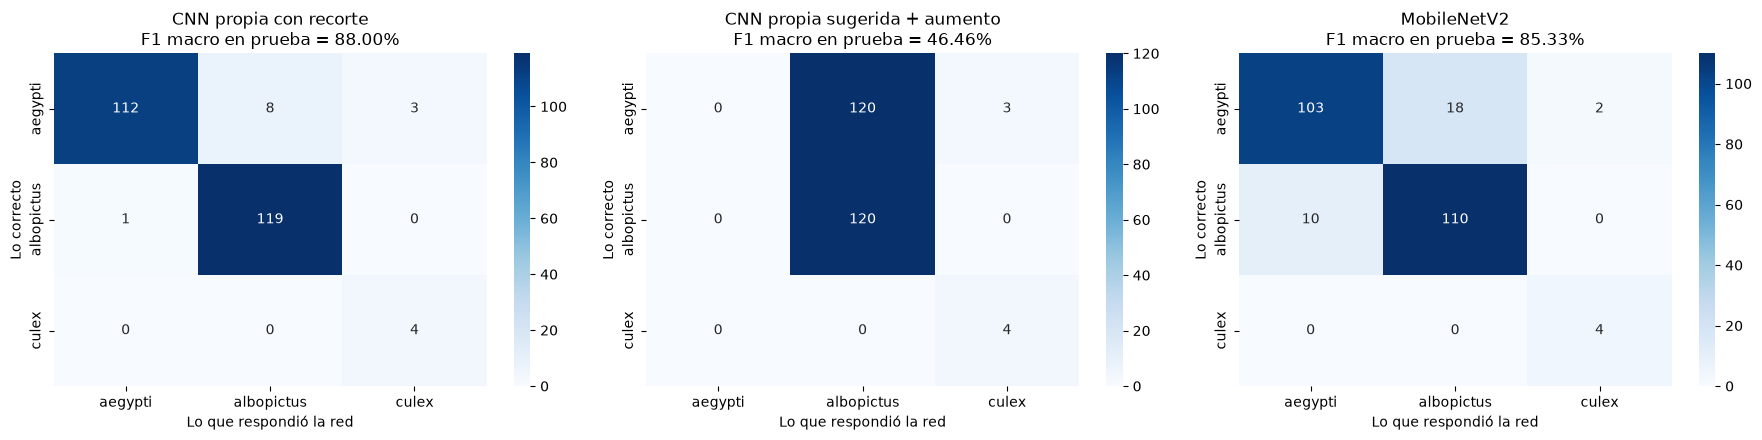

CNN propia con recorte: 88.00% -> cumple la meta de 85 %
CNN propia sugerida + aumento: 46.46% -> no cumple la meta de 85 %
MobileNetV2: 85.33% -> cumple la meta de 85 %


In [27]:
finales_x = [elegida_x, 'MobileNetV2']
if 'CNN propia sugerida + aumento' not in finales_x:
    finales_x.insert(1, 'CNN propia sugerida + aumento')    # referencia: la elegida en la sección 4 #

resumen_x = {}
fig, ejes = plt.subplots(1, len(finales_x), figsize=(6 * len(finales_x), 4.5))
for eje, nombre in zip(ejes, finales_x):
    archivo, mobilenet, recorte = modelos_x[nombre]
    datos = test_r if recorte else test_x
    modelo = tf.keras.models.load_model(CARPETA_MODELOS / archivo, compile=False)
    pred, f1 = evaluar(modelo, datos, mobilenet)
    f1_clase = f1_score(datos['etiqueta'], pred, average=None, labels=[0, 1, 2], zero_division=0)
    matriz = confusion_matrix(datos['etiqueta'], pred, labels=[0, 1, 2])
    print(f'===== {nombre}: F1 macro en prueba = {f1:.4f}  ({f1:.2%})')
    print(classification_report(datos['etiqueta'], pred, labels=[0, 1, 2], target_names=CLASES, zero_division=0))
    sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', xticklabels=CLASES, yticklabels=CLASES, ax=eje)
    eje.set_title(f'{nombre}\nF1 macro en prueba = {f1:.2%}')
    eje.set_xlabel('Lo que respondió la red')
    eje.set_ylabel('Lo correcto')
    resumen_x[nombre] = {'modelo': archivo, 'entrada': 'recorte' if recorte else 'foto completa',
                         'f1_macro': round(float(f1), 4),
                         'f1_por_clase': {c: round(float(v), 2) for c, v in zip(CLASES, f1_clase)},
                         'matriz_confusion': matriz.tolist()}
plt.tight_layout()
plt.show()

for nombre in finales_x:
    f1 = resumen_x[nombre]['f1_macro']
    print(f"{nombre}: {f1:.2%} -> {'cumple' if f1 >= 0.85 else 'no cumple'} la meta de 85 %")

## 5.6 Guardar los resultados del experimento

In [28]:
# Se agregan al mismo archivo, sin cambiar los resultados oficiales de la sección 4 #
with open(CARPETA_MODELOS / 'mosquitos_resultados.json', encoding='utf-8') as archivo:
    resultados_json = json.load(archivo)

resultados_json['experimento_recorte'] = {
    'descripcion': 'CNN propia con las fotos recortadas alrededor del mosquito (sección 5 del notebook 02)',
    'fotos_prueba': int(len(test_x)),
    'nota': 'Sin las 22 fotos de Culex de IEEE DataPort, que no se pudieron volver a descargar; '
            'todos los modelos se evaluaron con las mismas fotos.',
    'f1_validacion_aegypti_albopictus': {n: round(float(f), 4) for n, f in val_x_f1.items()},
    'elegida_con_validacion': elegida_x,
    'prueba': resumen_x,
}
with open(CARPETA_MODELOS / 'mosquitos_resultados.json', 'w', encoding='utf-8') as archivo:
    json.dump(resultados_json, archivo, indent=4, ensure_ascii=False)
print(json.dumps(resultados_json['experimento_recorte'], indent=2, ensure_ascii=False)[:2500])

{
  "descripcion": "CNN propia con las fotos recortadas alrededor del mosquito (sección 5 del notebook 02)",
  "fotos_prueba": 247,
  "nota": "Sin las 22 fotos de Culex de IEEE DataPort, que no se pudieron volver a descargar; todos los modelos se evaluaron con las mismas fotos.",
  "f1_validacion_aegypti_albopictus": {
    "CNN propia sugerida": 0.3348,
    "CNN propia sugerida + aumento": 0.3443,
    "CNN propia v2": 0.3693,
    "CNN propia con recorte": 0.9564,
    "MobileNetV2": 0.8974
  },
  "elegida_con_validacion": "CNN propia con recorte",
  "prueba": {
    "CNN propia con recorte": {
      "modelo": "cnn_mosquitos_recorte.keras",
      "entrada": "recorte",
      "f1_macro": 0.88,
      "f1_por_clase": {
        "aegypti": 0.95,
        "albopictus": 0.96,
        "culex": 0.73
      },
      "matriz_confusion": [
        [
          112,
          8,
          3
        ],
        [
          1,
          119,
          0
        ],
        [
          0,
          0,
        

## 5.7 Conclusiones del experimento

- **La CNN propia con recorte cumple la meta:** 88.00 % de F1 macro en prueba (247 fotos), sobre el 85 % del enunciado. F1 por especie: aegypti 0.95, albopictus 0.96 y Culex 0.73. Acertó 112 de 123 aegypti (8 las confundió con albopictus y 3 con Culex), 119 de 120 albopictus y las 4 Culex.
- **Con las mismas fotos**, MobileNetV2 obtuvo 85.33 % y la CNN propia elegida en la sección 4, 46.46 %. Recortar alrededor del mosquito resolvió justo el problema que mostró la matriz de la sección 4.7: separar aegypti de albopictus.
- **Se eligió con validación** (F1 de 0.956 con aegypti y albopictus, en la época 38 de 40) y se evaluó una sola vez en prueba.
- **Límites:**
  - Faltan las 22 fotos de Culex de IEEE DataPort, así que la prueba tiene 247 fotos en vez de 251 y solo 4 de Culex: su F1 de 0.73 depende de 3 errores. Los resultados oficiales de la sección 4 (251 fotos) no se cambiaron.
  - La validación no tiene Culex, y su F1 saltó mucho de una época a otra (de 0.32 a 0.96). El resultado podría cambiar con otra semilla.
  - La idea del recorte surgió de la matriz de confusión de la sección 4.7, aunque la validación ya mostraba el mismo problema.
  - Las 3 fotos de aegypti que llamó Culex son justo las de Mendeley, que tienen el mismo fondo blanco que todas las fotos de Culex. Para reconocer Culex, la red se apoya en parte en el fondo: una foto de aegypti sobre un fondo claro puede salir como Culex. MobileNetV2 tiene el mismo problema (llamó Culex a 2 de esas 3 fotos). La solución es tener fotos de cada especie con fondos variados.
  - El recorte funciona porque las fotos de Kaggle tienen un fondo parejo. Con fotos de campo habría que revisarlo; por eso la API sigue usando MobileNetV2, que recibe la foto completa.

# 6. Mosquito Alert: fotos con fondos variados para MobileNetV2

**Problema:** casi todas las fotos de *Culex* venían de Mendeley, sobre papel blanco, y casi todas las de *aegypti* y *albopictus* de Kaggle, sobre fondo azul. Las redes aprendieron en parte el fondo: MobileNetV2 llamó *Culex* a 2 de las 3 fotos de prueba de *aegypti* con fondo blanco (sección 5.7). Como la aplicación usa MobileNetV2, una foto de *aegypti* sobre un fondo claro podría salir como *Culex*.

**Solución:** agregar fotos de **Mosquito Alert 2023**, una de las fuentes que nombra el enunciado. Son fotos que toman personas con el celular, con fondos muy variados, y cada una trae la caja donde está el mosquito.

- Fuente: [AI Mosquito Alert Challenge Dataset 2023](https://zenodo.org/records/15063886) (Zenodo, licencia CC BY-NC-SA 4.0). *Mosquito Alert dataset, Mosquito Alert Community.*
- Tiene 4,612 fotos de *albopictus*, 4,563 de *Culex* y solo 47 de *aegypti* (el enunciado ya advierte que tiene muy pocas). Usamos las 47 de *aegypti* y 400 de cada una de las otras dos, elegidas al azar.
- Se separan en entrenamiento, validación y prueba (70 / 15 / 15 %). Las de prueba no se usan para nada más que la evaluación final.

**Qué se entrena:** MobileNetV2 tiene la base congelada (lo aprendido con ImageNet) y solo entrena la última capa. Aquí se vuelve a entrenar esa capa con las fotos de antes más las de Mosquito Alert. La entrada es la misma de la API (foto de 128 × 128 con `preprocess_input`), así que el modelo nuevo se puede usar en la aplicación sin cambiar nada más.

**Regla fijada antes de ver la prueba:** la aplicación usa el modelo nuevo solo si tiene mayor F1 macro en validación que el actual.

**No visto en clase:** calcular una vez las características de la base congelada y entrenar solo la capa final con ellas (es lo mismo que entrenar el modelo completo con la base congelada, pero mucho más rápido).

## 6.1 Fotos de Mosquito Alert

In [29]:
CARPETA_MA = Path('../data/raw/imagenes/fuentes/mosquito_alert')
anotaciones = pd.read_csv(CARPETA_MA / 'annotations.csv')
print('Fotos en Mosquito Alert:', len(anotaciones))
print(anotaciones['class_label'].value_counts().to_string())

# Las 3 especies del proyecto: todas las de aegypti y 400 al azar de albopictus y Culex #
POR_ESPECIE = {'aegypti': None, 'albopictus': 400, 'culex': 400}
partes_ma = []
for especie, cantidad in POR_ESPECIE.items():
    fotos = anotaciones[anotaciones['class_label'] == especie]
    partes_ma.append(fotos if cantidad is None else fotos.sample(cantidad, random_state=42))
ma = pd.concat(partes_ma, ignore_index=True)
ma['clase'] = ma['class_label']
ma['etiqueta'] = ma['clase'].map({c: i for i, c in enumerate(CLASES)})
ma['fuente'] = 'mosquito_alert'
ma['ruta_original'] = [str(CARPETA_MA / 'images' / Path(f).name) for f in ma['img_fName']]
ma = ma[[Path(r).is_file() for r in ma['ruta_original']]].reset_index(drop=True)

# 70 % entrenamiento, 15 % validación y 15 % prueba, con la misma proporción de especies en cada parte #
from sklearn.model_selection import train_test_split
ma_train, ma_resto = train_test_split(ma, test_size=0.30, stratify=ma['clase'], random_state=42)
ma_val, ma_test = train_test_split(ma_resto, test_size=0.50, stratify=ma_resto['clase'], random_state=42)
ma['split'] = 'train'
ma.loc[ma_val.index, 'split'] = 'validación'
ma.loc[ma_test.index, 'split'] = 'prueba'
ma[['img_fName', 'clase', 'split', 'bbx_xtl', 'bbx_ytl', 'bbx_xbr', 'bbx_ybr']].to_csv(
    '../data/processed/inventario_mosquito_alert.csv', index=False)
print(pd.crosstab(ma['clase'], ma['split']))

Fotos en Mosquito Alert: 10357
class_label
albopictus            4612
culex                 4563
culiseta               622
japonicus-koreicus     429
anopheles               84
aegypti                 47
split       prueba  train  validación
clase                                
aegypti          7     33           7
albopictus      61    279          60
culex           60    280          60


## 6.2 Preparar las fotos

Las fotos de Mosquito Alert son de celular y el mosquito suele ser pequeño. Para que se parezcan a una foto de un mosquito (como las que se suben a la app), se recorta un cuadrado alrededor de la caja del mosquito, **con bastante fondo alrededor** (el doble del tamaño del mosquito). Así la red ve fondos variados.

Los recortes se guardan una vez, a 256 × 256, en `data/raw/imagenes/preparadas/` (no se sube al repositorio). Las fotos de Kaggle y Mendeley se usan completas, exactamente como las recibe la API (reducidas a 128 × 128), para que sus resultados se puedan comparar con los de las secciones 4 y 5.

In [30]:
CARPETA_PREPARADAS = Path('../data/raw/imagenes/preparadas')


def preparar_ma(fila, destino):
    foto = Image.open(fila.ruta_original)
    foto.draft('RGB', (foto.size[0] // 2, foto.size[1] // 2))
    escala = foto.size[0] / fila.img_w
    foto = foto.convert('RGB')
    x0, y0, x1, y1 = (v * escala for v in (fila.bbx_xtl, fila.bbx_ytl, fila.bbx_xbr, fila.bbx_ybr))
    lado = min(2 * max(x1 - x0, y1 - y0), min(foto.size))    # el doble del mosquito, sin salirse de la foto #
    izquierda = np.clip((x0 + x1) / 2 - lado / 2, 0, foto.size[0] - lado)
    arriba = np.clip((y0 + y1) / 2 - lado / 2, 0, foto.size[1] - lado)
    recorte = foto.crop((int(izquierda), int(arriba), int(izquierda + lado), int(arriba + lado)))
    destino.parent.mkdir(parents=True, exist_ok=True)
    recorte.resize((256, 256), Image.LANCZOS).save(destino, quality=95)


ma['ruta'] = [str(CARPETA_PREPARADAS / 'mosquito_alert' / c / Path(f).name) for c, f in zip(ma['clase'], ma['img_fName'])]
for fila in ma.itertuples():
    if not Path(fila.ruta).is_file():
        preparar_ma(fila, Path(fila.ruta))


ma_train_p, ma_val_p, ma_test_p = (ma[ma['split'] == s].reset_index(drop=True)
                                   for s in ('train', 'validación', 'prueba'))
print('Recortes listos:', len(ma), 'fotos de Mosquito Alert')

Recortes listos: 847 fotos de Mosquito Alert


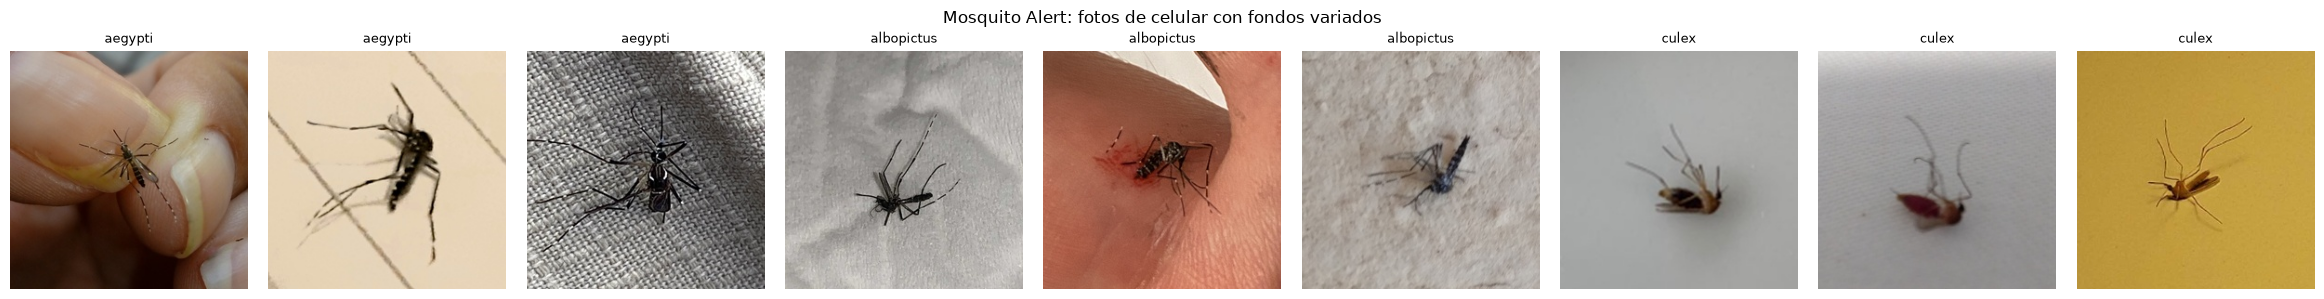

In [31]:
# Ejemplos de Mosquito Alert: fondos muy distintos a los de Kaggle y Mendeley #
ejemplos = ma_train_p.groupby('clase').head(3)
fig, ejes = plt.subplots(1, len(ejemplos), figsize=(2.6 * len(ejemplos), 3))
for eje, fila in zip(ejes, ejemplos.itertuples()):
    eje.imshow(Image.open(fila.ruta))
    eje.set_title(fila.clase, fontsize=9)
    eje.axis('off')
plt.suptitle('Mosquito Alert: fotos de celular con fondos variados')
plt.tight_layout()
plt.show()

## 6.3 Entrenar la última capa de MobileNetV2

1. Se calculan una vez las características de la base congelada de MobileNetV2 (1,280 números por foto).
2. Se entrena una capa final igual a la del modelo actual (Dropout 0.2 → Dense de 3), con pesos por clase y eligiendo la mejor época por el F1 macro en validación.
3. Se arma el modelo completo (base + capa nueva) y se guarda como `mobilenet_mosquitos_ma.keras`.

In [32]:
mobilenet_actual = tf.keras.models.load_model(CARPETA_MODELOS / 'mobilenet_mosquitos.keras', compile=False)
base = mobilenet_actual.layers[0]    # la base congelada de MobileNetV2 #
extractor = tf.keras.Sequential([base, tf.keras.layers.GlobalAveragePooling2D()])


def caracteristicas(datos):
    return extractor.predict(crear_dataset(datos, 128, mobilenet=True), verbose=0)


conjuntos = {'train': pd.concat([train_x, ma_train_p], ignore_index=True),
             'validación': pd.concat([val_x, ma_val_p], ignore_index=True)}
X_c = {n: caracteristicas(d) for n, d in conjuntos.items()}
y_c = {n: d['etiqueta'].values for n, d in conjuntos.items()}
print({n: X.shape for n, X in X_c.items()})

pesos_ma = compute_class_weight('balanced', classes=np.arange(3), y=y_c['train'])
pesos_clases_ma = {i: float(p) for i, p in enumerate(pesos_ma)}
print('Pesos por clase:', {CLASES[i]: round(p, 2) for i, p in pesos_clases_ma.items()})


class F1Caracteristicas(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        pred = np.argmax(self.model.predict(X_c['validación'], verbose=0), axis=1)
        logs['val_f1'] = f1_score(y_c['validación'], pred, average='macro', labels=[0, 1, 2], zero_division=0)


tf.keras.utils.set_random_seed(42)
capa_final = tf.keras.Sequential([tf.keras.Input(shape=(1280,)), tf.keras.layers.Dropout(0.2),
                                  tf.keras.layers.Dense(3, activation='softmax')])
capa_final.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
historia_ma = capa_final.fit(X_c['train'], y_c['train'], epochs=150, batch_size=32, class_weight=pesos_clases_ma,
                             validation_data=(X_c['validación'], y_c['validación']), verbose=0,
                             callbacks=[F1Caracteristicas(),
                                        EarlyStopping(monitor='val_f1', mode='max', patience=25,
                                                      restore_best_weights=True)])
f1_val = historia_ma.history['val_f1']
print('Épocas:', len(f1_val), '| mejor época:', int(np.argmax(f1_val)) + 1, '| mejor F1 en validación:', round(max(f1_val), 3))

# Modelo completo: la misma base + la capa final nueva (misma entrada que usa la API) #
mobilenet_ma = tf.keras.Sequential([tf.keras.Input(shape=(128, 128, 3)), base,
                                    tf.keras.layers.GlobalAveragePooling2D(), tf.keras.layers.Dropout(0.2),
                                    tf.keras.layers.Dense(3, activation='softmax')])
mobilenet_ma.layers[-1].set_weights(capa_final.layers[-1].get_weights())
mobilenet_ma.save(CARPETA_MODELOS / 'mobilenet_mosquitos_ma.keras')
print('Guardado: mobilenet_mosquitos_ma.keras')

{'train': (1418, 1280), 'validación': (289, 1280)}
Pesos por clase: {'aegypti': 1.06, 'albopictus': 0.7, 'culex': 1.6}


Épocas: 50 | mejor época: 25 | mejor F1 en validación: 0.861


Guardado: mobilenet_mosquitos_ma.keras


## 6.4 Comparación en validación y decisión

Las mismas fotos de validación (las de antes y las de Mosquito Alert) para el modelo actual y el nuevo.

In [33]:
def f1_de(modelo, datos):
    pred = np.argmax(modelo.predict(crear_dataset(datos, 128, mobilenet=True), verbose=0), axis=1)
    return f1_score(datos['etiqueta'], pred, average='macro', labels=[0, 1, 2], zero_division=0), pred


validacion_todo = conjuntos['validación']
f1_val_actual, _ = f1_de(mobilenet_actual, validacion_todo)
f1_val_nuevo, _ = f1_de(mobilenet_ma, validacion_todo)
print(f'F1 macro en validación -> MobileNetV2 actual: {f1_val_actual:.3f} | con Mosquito Alert: {f1_val_nuevo:.3f}')
usar_nuevo = f1_val_nuevo > f1_val_actual
print('La aplicación debe usar:', 'mobilenet_mosquitos_ma.keras' if usar_nuevo else 'mobilenet_mosquitos.keras')

F1 macro en validación -> MobileNetV2 actual: 0.700 | con Mosquito Alert: 0.861
La aplicación debe usar: mobilenet_mosquitos_ma.keras


## 6.5 Evaluación en prueba (una sola vez)

Tres grupos de fotos de prueba, ninguno usado para entrenar ni para elegir:

- **Kaggle y Mendeley:** las 247 fotos de prueba de la sección 5.
- **Mosquito Alert:** las fotos de prueba de esta sección, con fondos variados.
- **Fondo blanco (Mendeley):** las 7 fotos de prueba de Mendeley (3 *aegypti* y 4 *Culex*), donde se veía el problema del fondo.

In [34]:
grupos_prueba = {
    'Kaggle y Mendeley (247)': test_x,
    f'Mosquito Alert ({len(ma_test_p)})': ma_test_p,
    'Fondo blanco, Mendeley (7)': test_x[test_x['fuente'] == 'mendeley'].reset_index(drop=True),
}
resumen_ma = {}
for nombre_modelo, modelo in [('MobileNetV2 actual', mobilenet_actual), ('MobileNetV2 con Mosquito Alert', mobilenet_ma)]:
    for nombre_grupo, datos in grupos_prueba.items():
        f1, pred = f1_de(modelo, datos)
        aciertos = {c: f'{int(((pred == i) & (datos["etiqueta"] == i)).sum())}/{int((datos["etiqueta"] == i).sum())}'
                    for i, c in enumerate(CLASES)}
        resumen_ma[(nombre_modelo, nombre_grupo)] = {'f1_macro': round(float(f1), 4), 'aciertos': aciertos,
                                                    'matriz_confusion': confusion_matrix(datos['etiqueta'], pred,
                                                                                         labels=[0, 1, 2]).tolist()}
tabla_ma = pd.DataFrame({k: {'F1 macro': f'{v["f1_macro"]:.2%}', **v['aciertos']} for k, v in resumen_ma.items()}).T
tabla_ma

F1 macro  aegypti  \
MobileNetV2 actual             Kaggle y Mendeley (247)      85.33%  103/123   
                               Mosquito Alert (128)         24.96%      0/7   
                               Fondo blanco, Mendeley (7)   43.33%      1/3   
MobileNetV2 con Mosquito Alert Kaggle y Mendeley (247)      84.22%  110/123   
                               Mosquito Alert (128)         70.05%      2/7   
                               Fondo blanco, Mendeley (7)   46.30%      1/3   

                                                          albopictus  culex  
MobileNetV2 actual             Kaggle y Mendeley (247)       110/120    4/4  
                               Mosquito Alert (128)             3/61  57/60  
                               Fondo blanco, Mendeley (7)        0/0    4/4  
MobileNetV2 con Mosquito Alert Kaggle y Mendeley (247)        99/120    4/4  
                               Mosquito Alert (128)            50/61  58/60  
                               Fondo blanco, Mendeley (7)        0/0    4/4

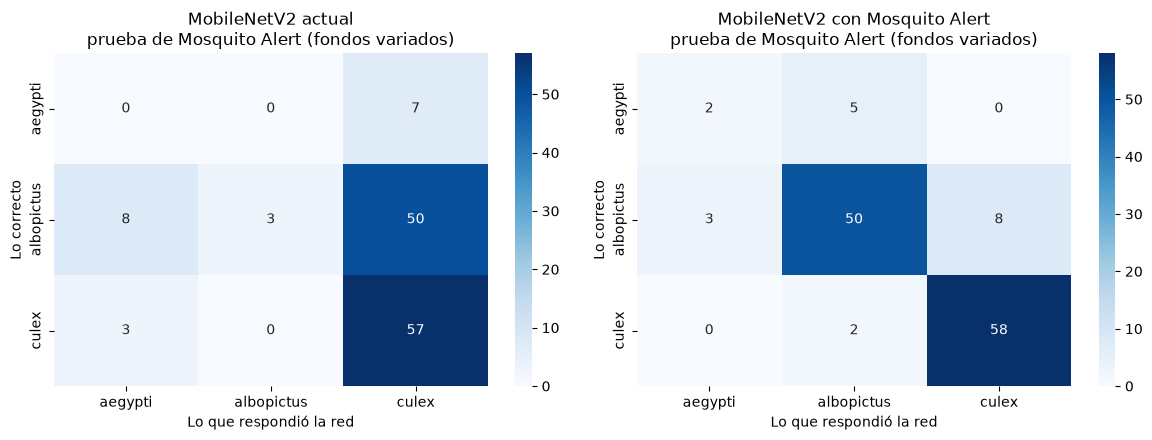

In [35]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
for eje, nombre_modelo in zip(ejes, ['MobileNetV2 actual', 'MobileNetV2 con Mosquito Alert']):
    matriz = np.array(resumen_ma[(nombre_modelo, f'Mosquito Alert ({len(ma_test_p)})')]['matriz_confusion'])
    sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', xticklabels=CLASES, yticklabels=CLASES, ax=eje)
    eje.set_title(f'{nombre_modelo}\nprueba de Mosquito Alert (fondos variados)')
    eje.set_xlabel('Lo que respondió la red')
    eje.set_ylabel('Lo correcto')
plt.tight_layout()
plt.show()

## 6.6 Guardar los resultados

In [36]:
with open(CARPETA_MODELOS / 'mosquitos_resultados.json', encoding='utf-8') as archivo:
    resultados_json = json.load(archivo)

resultados_json['experimento_mosquito_alert'] = {
    'descripcion': 'MobileNetV2 con la última capa reentrenada agregando fotos de Mosquito Alert 2023 (sección 6 del notebook 02)',
    'fuente': 'AI Mosquito Alert Challenge Dataset 2023 (Zenodo 15063886, CC BY-NC-SA 4.0)',
    'fotos_mosquito_alert': {s: int((ma['split'] == s).sum()) for s in ('train', 'validación', 'prueba')},
    'f1_validacion': {'MobileNetV2 actual': round(float(f1_val_actual), 4),
                      'MobileNetV2 con Mosquito Alert': round(float(f1_val_nuevo), 4)},
    'modelo_para_la_app': 'mobilenet_mosquitos_ma.keras' if usar_nuevo else 'mobilenet_mosquitos.keras',
    'prueba': {f'{m} | {g}': v for (m, g), v in resumen_ma.items()},
}
with open(CARPETA_MODELOS / 'mosquitos_resultados.json', 'w', encoding='utf-8') as archivo:
    json.dump(resultados_json, archivo, indent=4, ensure_ascii=False)
print(json.dumps(resultados_json['experimento_mosquito_alert']['f1_validacion'], ensure_ascii=False))
print('Modelo para la app:', resultados_json['experimento_mosquito_alert']['modelo_para_la_app'])

{"MobileNetV2 actual": 0.6999, "MobileNetV2 con Mosquito Alert": 0.8606}
Modelo para la app: mobilenet_mosquitos_ma.keras


## 6.7 Conclusiones

- **Con fotos reales, la MobileNetV2 original fallaba:** en las 128 fotos de prueba de Mosquito Alert (fotos de celular con fondos variados) obtuvo 24.96 % de F1 macro. Llamó *Culex* a las 7 de *aegypti* y a 50 de las 61 de *albopictus*. Esto confirma el sesgo por el fondo: lo que no tenía el fondo azul de Kaggle, lo llamaba *Culex*.
- **Reentrenada con Mosquito Alert sube a 70.05 %:** acierta 50 de 61 *albopictus*, 58 de 60 *Culex* y 2 de 7 *aegypti*.
- **Se eligió con validación** (F1 de 0.861 contra 0.700), con la regla fijada antes de ver la prueba. Por eso la aplicación usó `mobilenet_mosquitos_ma.keras`, hasta que el ajuste fino de la sección 6.8 lo superó en validación.
- **El costo:** en las 247 fotos de Kaggle y Mendeley baja un poco, de 85.33 % a 84.22 %: gana en *aegypti* (110 contra 103) y pierde en *albopictus* (99 contra 110), y queda justo por debajo de la meta del 85 %. Preferimos el modelo que funciona con fotos reales.
- **Lo que sigue difícil:** *aegypti* con fondos variados (2 de 7), porque Mosquito Alert solo tiene 47 fotos de esa especie (33 para entrenar), como advierte el enunciado. De las 3 fotos de *aegypti* con fondo blanco acierta 1: una la llama *albopictus* y otra *Culex* (antes eran 2 *Culex*).
- Las 3 fotos preparadas para la demo las clasifica bien, con más de 99 % de confianza.

## 6.8 Ajuste fino: entrenar también las últimas capas de MobileNetV2

En 6.3 solo se entrenó la capa final. Para sacar más de las fotos disponibles:

- Se **descongelan las últimas capas de la base** (desde el bloque 13) y se entrenan con una tasa de aprendizaje pequeña (0.0001), partiendo del modelo de 6.3. Las capas de BatchNormalization se quedan congeladas.
- Se usa **aumento de datos** (giro horizontal, rotación y zoom), para que cada foto rinda más.
- Las pocas fotos de *aegypti* de Mosquito Alert (33 para entrenar) pesan **3 veces más**, porque *aegypti* con fondos variados es lo más difícil.
- La mejor época se elige con el F1 macro en validación.

**Regla fijada antes de ver la prueba:** la aplicación usa el modelo con ajuste fino solo si su F1 en validación es mayor que el del modelo de 6.3.

**No visto en clase:** ajuste fino (*fine-tuning*) de una red preentrenada y pesos por foto (`sample_weight`).

In [37]:
from tensorflow.keras import layers

mobilenet_ma = tf.keras.models.load_model(CARPETA_MODELOS / 'mobilenet_mosquitos_ma.keras', compile=False)
validacion_todo = pd.concat([val_x, ma_val_p], ignore_index=True)
entrenamiento_todo = pd.concat([train_x, ma_train_p], ignore_index=True)

pesos_clase = compute_class_weight('balanced', classes=np.arange(3), y=entrenamiento_todo['etiqueta'])
pesos_foto = np.array([pesos_clase[e] * (3.0 if (f == 'mosquito_alert' and e == 0) else 1.0)
                       for f, e in zip(entrenamiento_todo['fuente'], entrenamiento_todo['etiqueta'])], dtype='float32')

# Las fotos se leen una sola vez y se guardan en memoria (cache): las de Kaggle son muy grandes #
ds_entrenamiento = (tf.data.Dataset.from_tensor_slices((entrenamiento_todo['ruta'].values,
                                                        entrenamiento_todo['etiqueta'].values.astype('int32'), pesos_foto))
                    .map(lambda r, e, w: (leer_foto(r, 128, True), e, w), num_parallel_calls=tf.data.AUTOTUNE)
                    .cache().shuffle(len(entrenamiento_todo), seed=42).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
ds_validacion = crear_dataset(validacion_todo, 128, mobilenet=True).cache()

# Modelo: aumento de datos + la base (las últimas capas entrenables) + la capa final de 6.3 #
tf.keras.utils.set_random_seed(42)
base_ft = tf.keras.models.load_model(CARPETA_MODELOS / 'mobilenet_mosquitos_ma.keras', compile=False).layers[0]
base_ft.trainable = True
desde = [capa.name for capa in base_ft.layers].index('block_13_expand')
for i, capa in enumerate(base_ft.layers):
    capa.trainable = i >= desde and not isinstance(capa, layers.BatchNormalization)

entrada = tf.keras.Input(shape=(128, 128, 3))
x = layers.RandomFlip('horizontal')(entrada)
x = layers.RandomRotation(0.1)(x)
x = layers.RandomZoom(0.15)(x)
x = base_ft(x, training=False)    # BatchNormalization en modo de uso, no de entrenamiento #
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
salida = layers.Dense(3, activation='softmax')(x)
modelo_ft = tf.keras.Model(entrada, salida)
modelo_ft.layers[-1].set_weights(mobilenet_ma.layers[-1].get_weights())
modelo_ft.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print('Pesos entrenables:', sum(int(np.prod(p.shape)) for p in modelo_ft.trainable_weights))


class F1ValidacionFT(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        pred = np.argmax(self.model.predict(ds_validacion, verbose=0), axis=1)
        logs['val_f1'] = f1_score(validacion_todo['etiqueta'], pred, average='macro', labels=[0, 1, 2], zero_division=0)


archivo_ft = 'mobilenet_mosquitos_ma_ft.keras'
historia_ft = modelo_ft.fit(ds_entrenamiento, epochs=25, validation_data=ds_validacion, verbose=2,
                            callbacks=[F1ValidacionFT(),
                                       EarlyStopping(monitor='val_f1', mode='max', patience=6),
                                       ModelCheckpoint(str(CARPETA_MODELOS / archivo_ft), monitor='val_f1', mode='max',
                                                       save_best_only=True)])
f1_epocas = historia_ft.history['val_f1']
print('Épocas:', len(f1_epocas), '| mejor época:', int(np.argmax(f1_epocas)) + 1,
      '| mejor F1 en validación:', round(max(f1_epocas), 3))

Pesos entrenables: 1667203
Epoch 1/25


C:\Users\jerem\Desktop\dengue\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


45/45 - 27s - 607ms/step - accuracy: 0.7313 - loss: 0.7078 - val_accuracy: 0.5848 - val_loss: 1.0313 - val_f1: 0.6021


Epoch 2/25


45/45 - 8s - 167ms/step - accuracy: 0.7821 - loss: 0.5205 - val_accuracy: 0.7820 - val_loss: 0.4816 - val_f1: 0.7915


Epoch 3/25


... (42 outputs left out)

45/45 - 7s - 162ms/step - accuracy: 0.9612 - loss: 0.1023 - val_accuracy: 0.8962 - val_loss: 0.3937 - val_f1: 0.8942


Epoch 25/25


45/45 - 7s - 151ms/step - accuracy: 0.9647 - loss: 0.0871 - val_accuracy: 0.8927 - val_loss: 0.4885 - val_f1: 0.8914


Épocas: 25 | mejor época: 24 | mejor F1 en validación: 0.894


In [38]:
modelo_ft = tf.keras.models.load_model(CARPETA_MODELOS / archivo_ft, compile=False)


def f1_y_pred(modelo, datos):
    pred = np.argmax(modelo.predict(crear_dataset(datos, 128, mobilenet=True), verbose=0), axis=1)
    return f1_score(datos['etiqueta'], pred, average='macro', labels=[0, 1, 2], zero_division=0), pred


f1_val_63, _ = f1_y_pred(mobilenet_ma, validacion_todo)
f1_val_ft, _ = f1_y_pred(modelo_ft, validacion_todo)
usar_ft = f1_val_ft > f1_val_63
print(f'F1 macro en validación -> capa final (6.3): {f1_val_63:.3f} | ajuste fino: {f1_val_ft:.3f}')
print('La aplicación debe usar:', archivo_ft if usar_ft else 'mobilenet_mosquitos_ma.keras')

F1 macro en validación -> capa final (6.3): 0.861 | ajuste fino: 0.894
La aplicación debe usar: mobilenet_mosquitos_ma_ft.keras


### Evaluación en prueba (una sola vez)

Los mismos tres grupos de fotos de prueba de 6.5.

In [39]:
grupos_prueba = {
    'Kaggle y Mendeley (247)': test_x,
    f'Mosquito Alert ({len(ma_test_p)})': ma_test_p,
    'Fondo blanco, Mendeley (7)': test_x[test_x['fuente'] == 'mendeley'].reset_index(drop=True),
}
resumen_ft = {}
for nombre_modelo, modelo in [('MobileNetV2 con Mosquito Alert (6.3)', mobilenet_ma),
                              ('MobileNetV2 con ajuste fino (6.8)', modelo_ft)]:
    for nombre_grupo, datos in grupos_prueba.items():
        f1, pred = f1_y_pred(modelo, datos)
        aciertos = {c: f'{int(((pred == i) & (datos["etiqueta"] == i)).sum())}/{int((datos["etiqueta"] == i).sum())}'
                    for i, c in enumerate(CLASES)}
        resumen_ft[(nombre_modelo, nombre_grupo)] = {'f1_macro': round(float(f1), 4), 'aciertos': aciertos,
                                                    'matriz_confusion': confusion_matrix(datos['etiqueta'], pred,
                                                                                         labels=[0, 1, 2]).tolist()}
pd.DataFrame({k: {'F1 macro': f'{v["f1_macro"]:.2%}', **v['aciertos']} for k, v in resumen_ft.items()}).T

F1 macro  \
MobileNetV2 con Mosquito Alert (6.3) Kaggle y Mendeley (247)      84.22%   
                                     Mosquito Alert (128)         70.05%   
                                     Fondo blanco, Mendeley (7)   46.30%   
MobileNetV2 con ajuste fino (6.8)    Kaggle y Mendeley (247)      87.46%   
                                     Mosquito Alert (128)         59.43%   
                                     Fondo blanco, Mendeley (7)   43.33%   

                                                                 aegypti  \
MobileNetV2 con Mosquito Alert (6.3) Kaggle y Mendeley (247)     110/123   
                                     Mosquito Alert (128)            2/7   
                                     Fondo blanco, Mendeley (7)      1/3   
MobileNetV2 con ajuste fino (6.8)    Kaggle y Mendeley (247)     113/123   
                                     Mosquito Alert (128)            0/7   
                                     Fondo blanco, Mendeley (7)      1/3   

                                                                albopictus  \
MobileNetV2 con Mosquito Alert (6.3) Kaggle y Mendeley (247)        99/120   
                                     Mosquito Alert (128)            50/61   
                                     Fondo blanco, Mendeley (7)        0/0   
MobileNetV2 con ajuste fino (6.8)    Kaggle y Mendeley (247)       116/120   
                                     Mosquito Alert (128)            54/61   
                                     Fondo blanco, Mendeley (7)        0/0   

                                                                 culex  
MobileNetV2 con Mosquito Alert (6.3) Kaggle y Mendeley (247)       4/4  
                                     Mosquito Alert (128)        58/60  
                                     Fondo blanco, Mendeley (7)    4/4  
MobileNetV2 con ajuste fino (6.8)    Kaggle y Mendeley (247)       4/4  
                                     Mosquito Alert (128)        57/60  
                                     Fondo blanco, Mendeley (7)    4/4

In [40]:
with open(CARPETA_MODELOS / 'mosquitos_resultados.json', encoding='utf-8') as archivo:
    resultados_json = json.load(archivo)

experimento = resultados_json['experimento_mosquito_alert']
experimento['ajuste_fino'] = {
    'descripcion': 'Ajuste fino de las últimas capas de MobileNetV2 con aumento de datos (sección 6.8 del notebook 02)',
    'f1_validacion': {'capa final (6.3)': round(float(f1_val_63), 4), 'ajuste fino (6.8)': round(float(f1_val_ft), 4)},
    'prueba': {f'{m} | {g}': v for (m, g), v in resumen_ft.items()},
}
experimento['modelo_para_la_app'] = archivo_ft if usar_ft else 'mobilenet_mosquitos_ma.keras'
etiqueta_app = 'MobileNetV2 con ajuste fino (6.8)' if usar_ft else 'MobileNetV2 con Mosquito Alert (6.3)'
experimento['f1_prueba_app'] = {g: resumen_ft[(etiqueta_app, g)]['f1_macro'] for g in grupos_prueba}
with open(CARPETA_MODELOS / 'mosquitos_resultados.json', 'w', encoding='utf-8') as archivo:
    json.dump(resultados_json, archivo, indent=4, ensure_ascii=False)
print('Modelo para la app:', experimento['modelo_para_la_app'])
print(experimento['f1_prueba_app'])

Modelo para la app: mobilenet_mosquitos_ma_ft.keras
{'Kaggle y Mendeley (247)': 0.8746, 'Mosquito Alert (128)': 0.5943, 'Fondo blanco, Mendeley (7)': 0.4333}


### Conclusiones del ajuste fino

- **Con validación ganó el ajuste fino** (F1 de 0.894 contra 0.861 de la capa final sola), así que la aplicación usa `mobilenet_mosquitos_ma_ft.keras`.
- **En las 247 fotos de Kaggle y Mendeley llega a 87.46 %**, por encima de la meta del 85 %: acierta 113 de 123 *aegypti*, 116 de 120 *albopictus* y las 4 *Culex*.
- **Con fotos de celular (Mosquito Alert)** acierta 54 de 61 *albopictus* y 57 de 60 *Culex* (111 de 128 en total, contra 110 del modelo de 6.3), pero ninguna de las 7 *aegypti*. Por eso su F1 macro con esas fotos es 59.43 %, contra 70.05 % del modelo de 6.3, que acertaba 2 de 7. En validación, las dos versiones aciertan 1 de las 7 *aegypti*: con tan pocas fotos, la diferencia es casi azar y el límite son los datos (Mosquito Alert solo tiene 47 fotos de *aegypti*).
- Las 3 fotos preparadas para la demo las clasifica bien, con 100 % de confianza.
- Para mejorar *aegypti* con fondos variados hacen falta más fotos de esa especie con fondos variados.